# 0. 개요

KAMP 사출성형 불량예측 (650톤-우진2호기, cn7·rg3 금형)

- 문제 정의: 대회 그대로 "사출 1회 불량 예측". 결과 해석은 "불량 구간 경보" 관점까지 확장
- 핵심 발견
  - cn7 불량 14사출은 10/16 05:21~05:57, 36분 안에 몰려 있음 → 사실상 불량 사건 1번
  - 시간이 가까운 사출은 센서 값이 거의 같음 → 랜덤 분할 시 점수가 부풀려짐 (랜덤 0.285 → 30분 묶음 분할 0.043, 찍기 수준 0.023)
  - 비라벨 안에 라벨 사출이 정답 칸만 빠진 채 들어 있음 → 비라벨 전체로 비지도 학습하면 누수
- 평가 원칙: 학습과 모델 선택은 대회 제공 범위로만 수행, KAMP 원본에만 있는 이후 기간은 미래 시험에만 사용



# 1. 데이터 준비

- KAMP 제공 폴더에서 대회 파일과 원본을 꺼냄. 
- 라벨은 원본(전체 기간)을 쓰고, 대회 범위 이후 기간은 미래 시험에만 씀.


### 1-1 대회 데이터 복사

In [1]:
import os, shutil
import pandas as pd

SRC = '/mnt/datasets/04/'
os.makedirs('data_contest', exist_ok=True)
os.makedirs('data_raw_extracted', exist_ok=True)

# (A) 대회용 데이터셋 → 대조·참고용
for f in ['moldset_labeled_cn7.csv', 'moldset_labeled_rg3.csv',
          'moldset_unlabeled_cn7.csv', 'moldset_unlabeled_rg3.csv']:
    shutil.copy(SRC + f, 'data_contest/' + f)
    print('대회용', f, pd.read_csv('data_contest/' + f, index_col=0).shape)

대회용 moldset_labeled_cn7.csv (1211, 25)
대회용 moldset_labeled_rg3.csv (1182, 25)
대회용 moldset_unlabeled_cn7.csv (35239, 24)
대회용 moldset_unlabeled_rg3.csv (35941, 24)


### 1-2. 원본에서 대회 범위 추출

- 650톤-우진2호기 + 금형별 부품번호로 라벨·비라벨 원본을 뽑는다. 비라벨은 여기 것을 사용.

In [2]:
# (B) 원본에서 대회 범위 추출 → 비라벨은 여기 것을 사용
MACHINE = '650톤-우진2호기'
PARTS = {'cn7': ['86131AA000', '86141AA000'],
         'rg3': ['86131T1000', '86141T1000']}
lab = pd.read_csv(SRC + 'moldset_labeled.csv', low_memory=False)
unl = pd.read_csv(SRC + 'unlabeled_data.csv', low_memory=False)
for k, codes in PARTS.items():
    for name, df in [('labeled', lab), ('unlabeled', unl)]:
        sub = df[(df['EQUIP_NAME'] == MACHINE) & (df['PART_NO'].isin(codes))]
        sub = sub.drop(columns=[c for c in sub.columns if c.startswith('Unnamed')])
        sub.to_csv(f'data_raw_extracted/{name}_{k}_raw.csv', index=False, encoding='utf-8-sig')
        print('원본추출', name, k, sub.shape)

원본추출 labeled cn7 (1425, 46)
원본추출 unlabeled cn7 (35239, 45)
원본추출 labeled rg3 (1182, 46)
원본추출 unlabeled rg3 (35941, 45)


### 1-3. 라벨 원본 전체 기간 추출
- 대회 범위 이후 기간까지 포함한 라벨 원본. 라벨은 이걸 사용하고, 이후 기간은 미래 시험용.

In [3]:
# (C) 라벨 원본(전체 기간) → 라벨은 이걸 사용
ld = pd.read_csv(SRC + 'labeled_data.csv', low_memory=False)
ld = ld.drop(columns=[c for c in ld.columns if c.startswith('Unnamed')])
for k, prefix in [('cn7', 'CN7'), ('rg3', 'RG3')]:
    sub = ld[(ld['EQUIP_NAME'] == MACHINE) & (ld['PART_NAME'].str.startswith(prefix))]
    sub.to_csv(f'data_raw_extracted/labeled_full_{k}_raw.csv', index=False, encoding='utf-8-sig')
    print('라벨원본(전체기간)', k, sub.shape)

라벨원본(전체기간) cn7 (6736, 45)
라벨원본(전체기간) rg3 (1256, 45)


### 1-4. 과거 비라벨 운전 조건 확인 (실행 전 확정 ① 근거)
라벨 기간 시작 전 비라벨과 대회 라벨 범위를 변수별로 비교한다. 비라벨 절반은 운전 조건이 달라서, 라벨과 같은 조건만 골라 써야 하는 근거(보고서 그래프 3).


===== cn7: 라벨 1211행 / 과거 비라벨 21268행 (2020-03-24 ~ 2020-10-16)
                      변수      라벨_중앙  비라벨_중앙   가까움    중간   아주멂         분류힌트
          Injection_Time   9.540000     5.0 0.117 0.078 0.805    서서히 변함 후보
            Filling_Time   4.430000     5.0 0.091 0.782 0.127    서서히 변함 후보
       Plasticizing_Time  17.010000     2.7 0.192 0.061 0.747    서서히 변함 후보
              Cycle_Time  59.520000    36.6 0.028 0.226 0.746    서서히 변함 후보
        Clamp_Close_Time   7.120000     3.1 0.193 0.061 0.746    서서히 변함 후보
        Cushion_Position 653.409973    17.3 0.254 0.000 0.746 뚝 끊김(설정형) 후보
   Plasticizing_Position  68.489998    38.5 0.160 0.093 0.747    서서히 변함 후보
     Clamp_Open_Position 647.989990   491.8 0.193 0.107 0.700    서서히 변함 후보
     Max_Injection_Speed  56.000000    37.1 0.115 0.842 0.043    서서히 변함 후보
           Max_Screw_RPM  30.799999     0.0 0.250 0.000 0.750 뚝 끊김(설정형) 후보
       Average_Screw_RPM 292.500000     0.0 0.250 0.000 0.750 뚝 끊김(설정형) 후보
  Max_Injection_Pressure 141.800003  

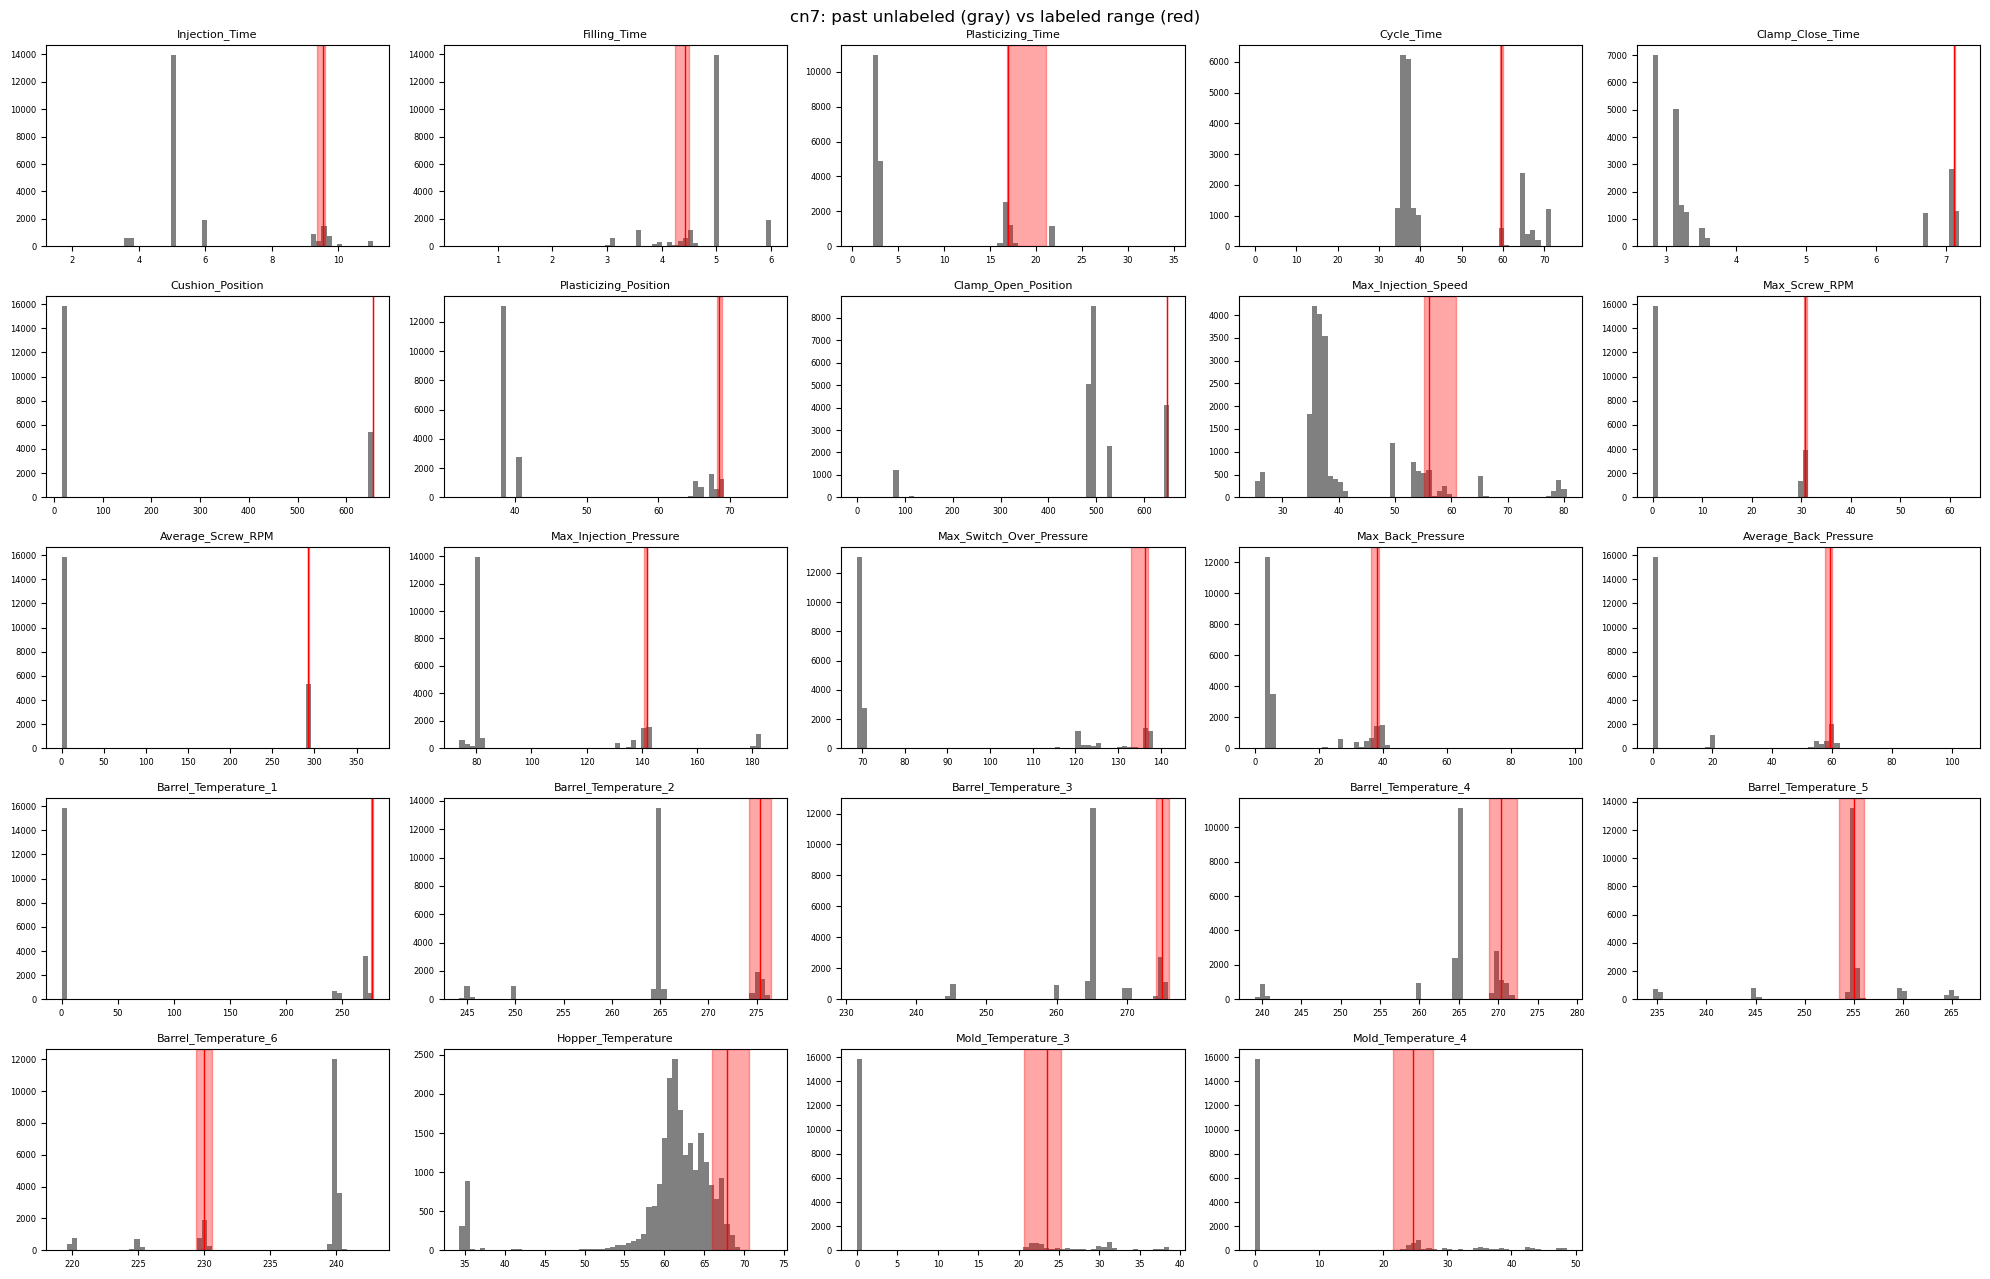

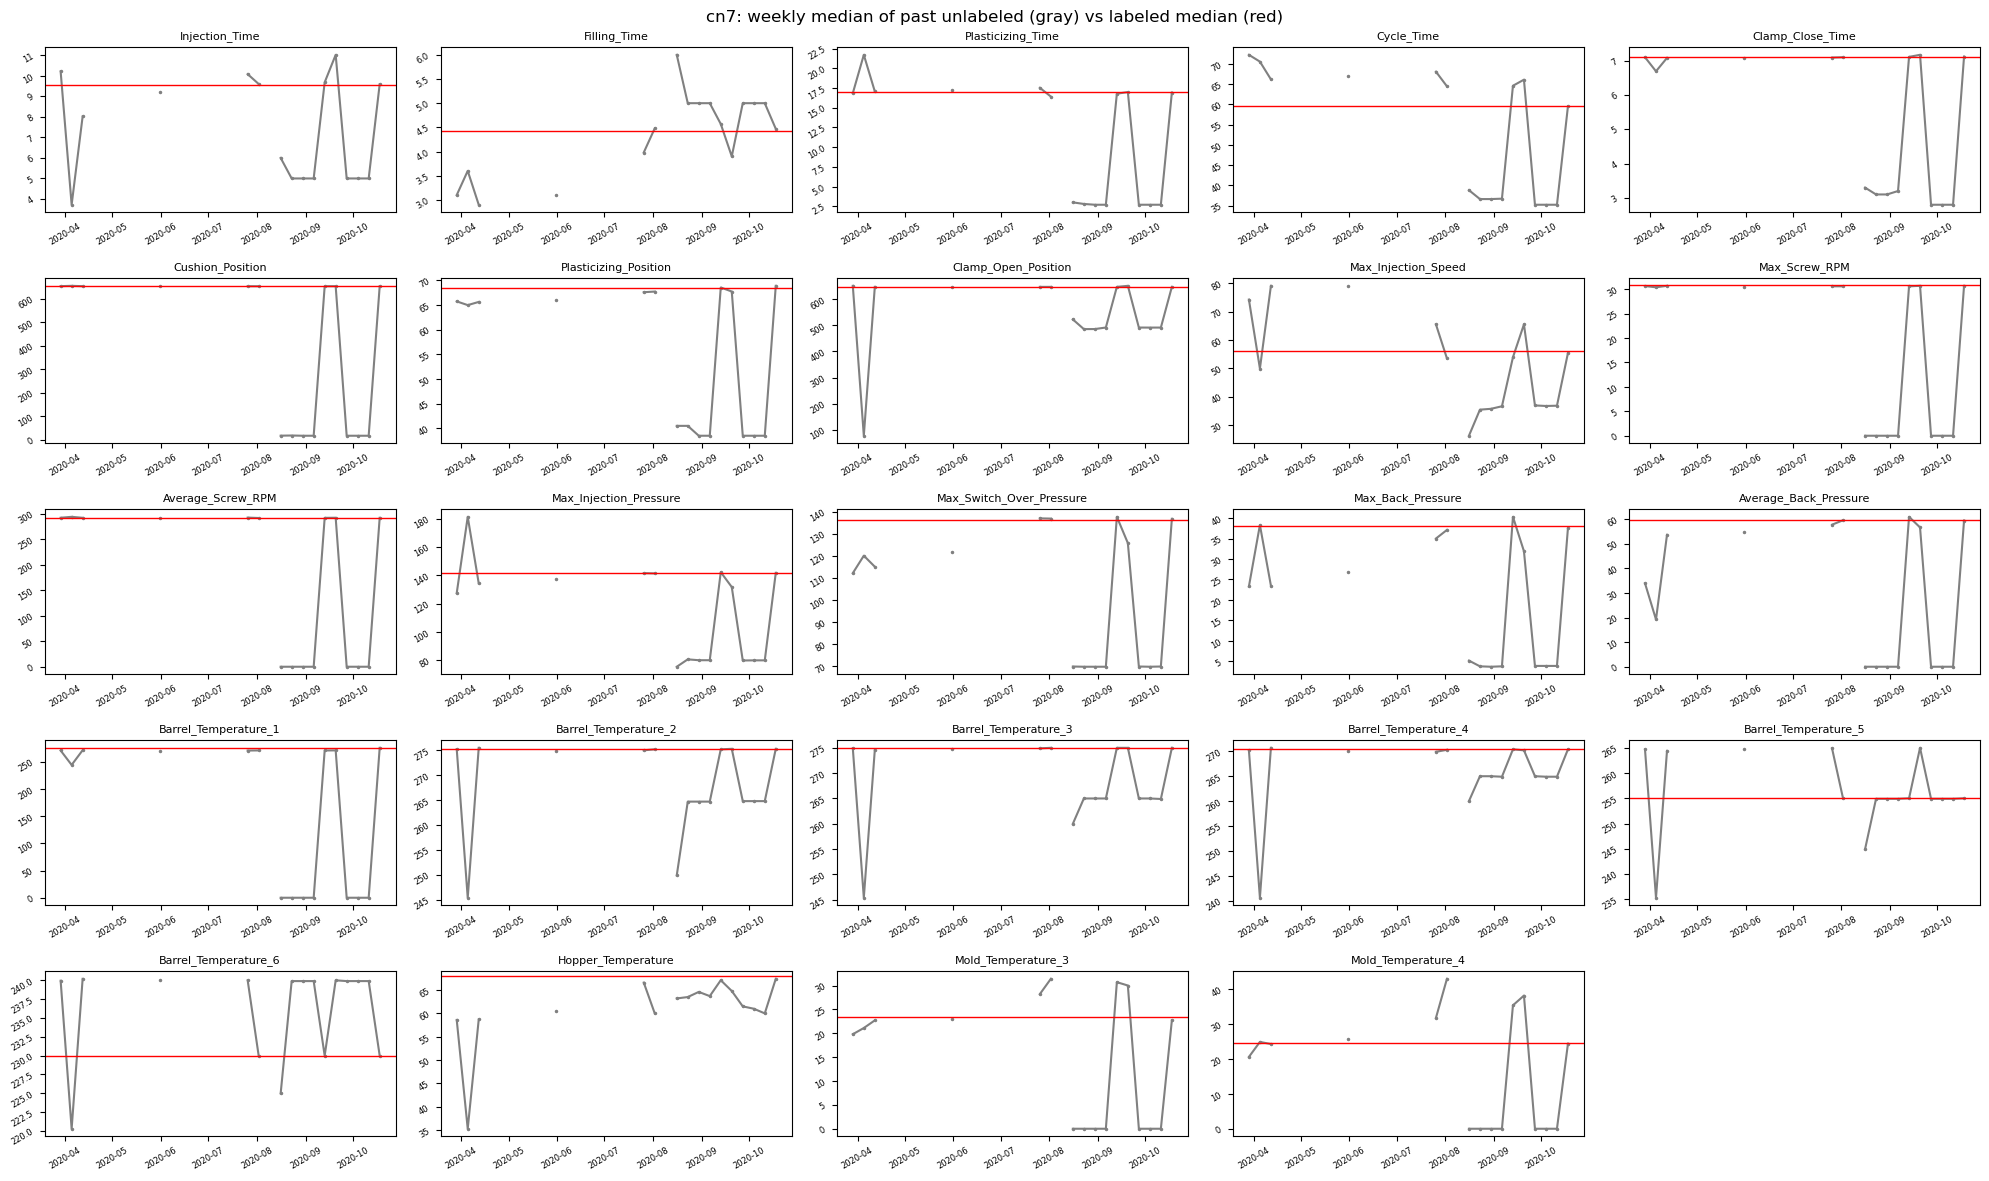


===== rg3: 라벨 1182행 / 과거 비라벨 30242행 (2020-03-25 ~ 2020-10-21)
                      변수      라벨_중앙  비라벨_중앙   가까움    중간   아주멂         분류힌트
          Injection_Time   1.060000    5.00 0.231 0.196 0.573    서서히 변함 후보
            Filling_Time   0.940000    2.37 0.231 0.196 0.573    서서히 변함 후보
       Plasticizing_Time  12.920000   12.72 0.253 0.174 0.573    서서히 변함 후보
              Cycle_Time  61.779999   60.91 0.137 0.413 0.450    서서히 변함 후보
        Clamp_Close_Time   6.800000    6.11 0.430 0.135 0.435    서서히 변함 후보
        Cushion_Position 654.250000  654.25 0.565 0.000 0.435 뚝 끊김(설정형) 후보
   Plasticizing_Position  53.580002   52.49 0.375 0.140 0.485    서서히 변함 후보
     Clamp_Open_Position   4.630000   66.63 0.130 0.000 0.870 뚝 끊김(설정형) 후보
     Max_Injection_Speed 128.199997   73.00 0.422 0.005 0.573 뚝 끊김(설정형) 후보
           Max_Screw_RPM  30.799999   30.60 0.446 0.000 0.554 뚝 끊김(설정형) 후보
       Average_Screw_RPM 290.500000  290.30 0.446 0.000 0.554 뚝 끊김(설정형) 후보
  Max_Injection_Pressure 142.600006  

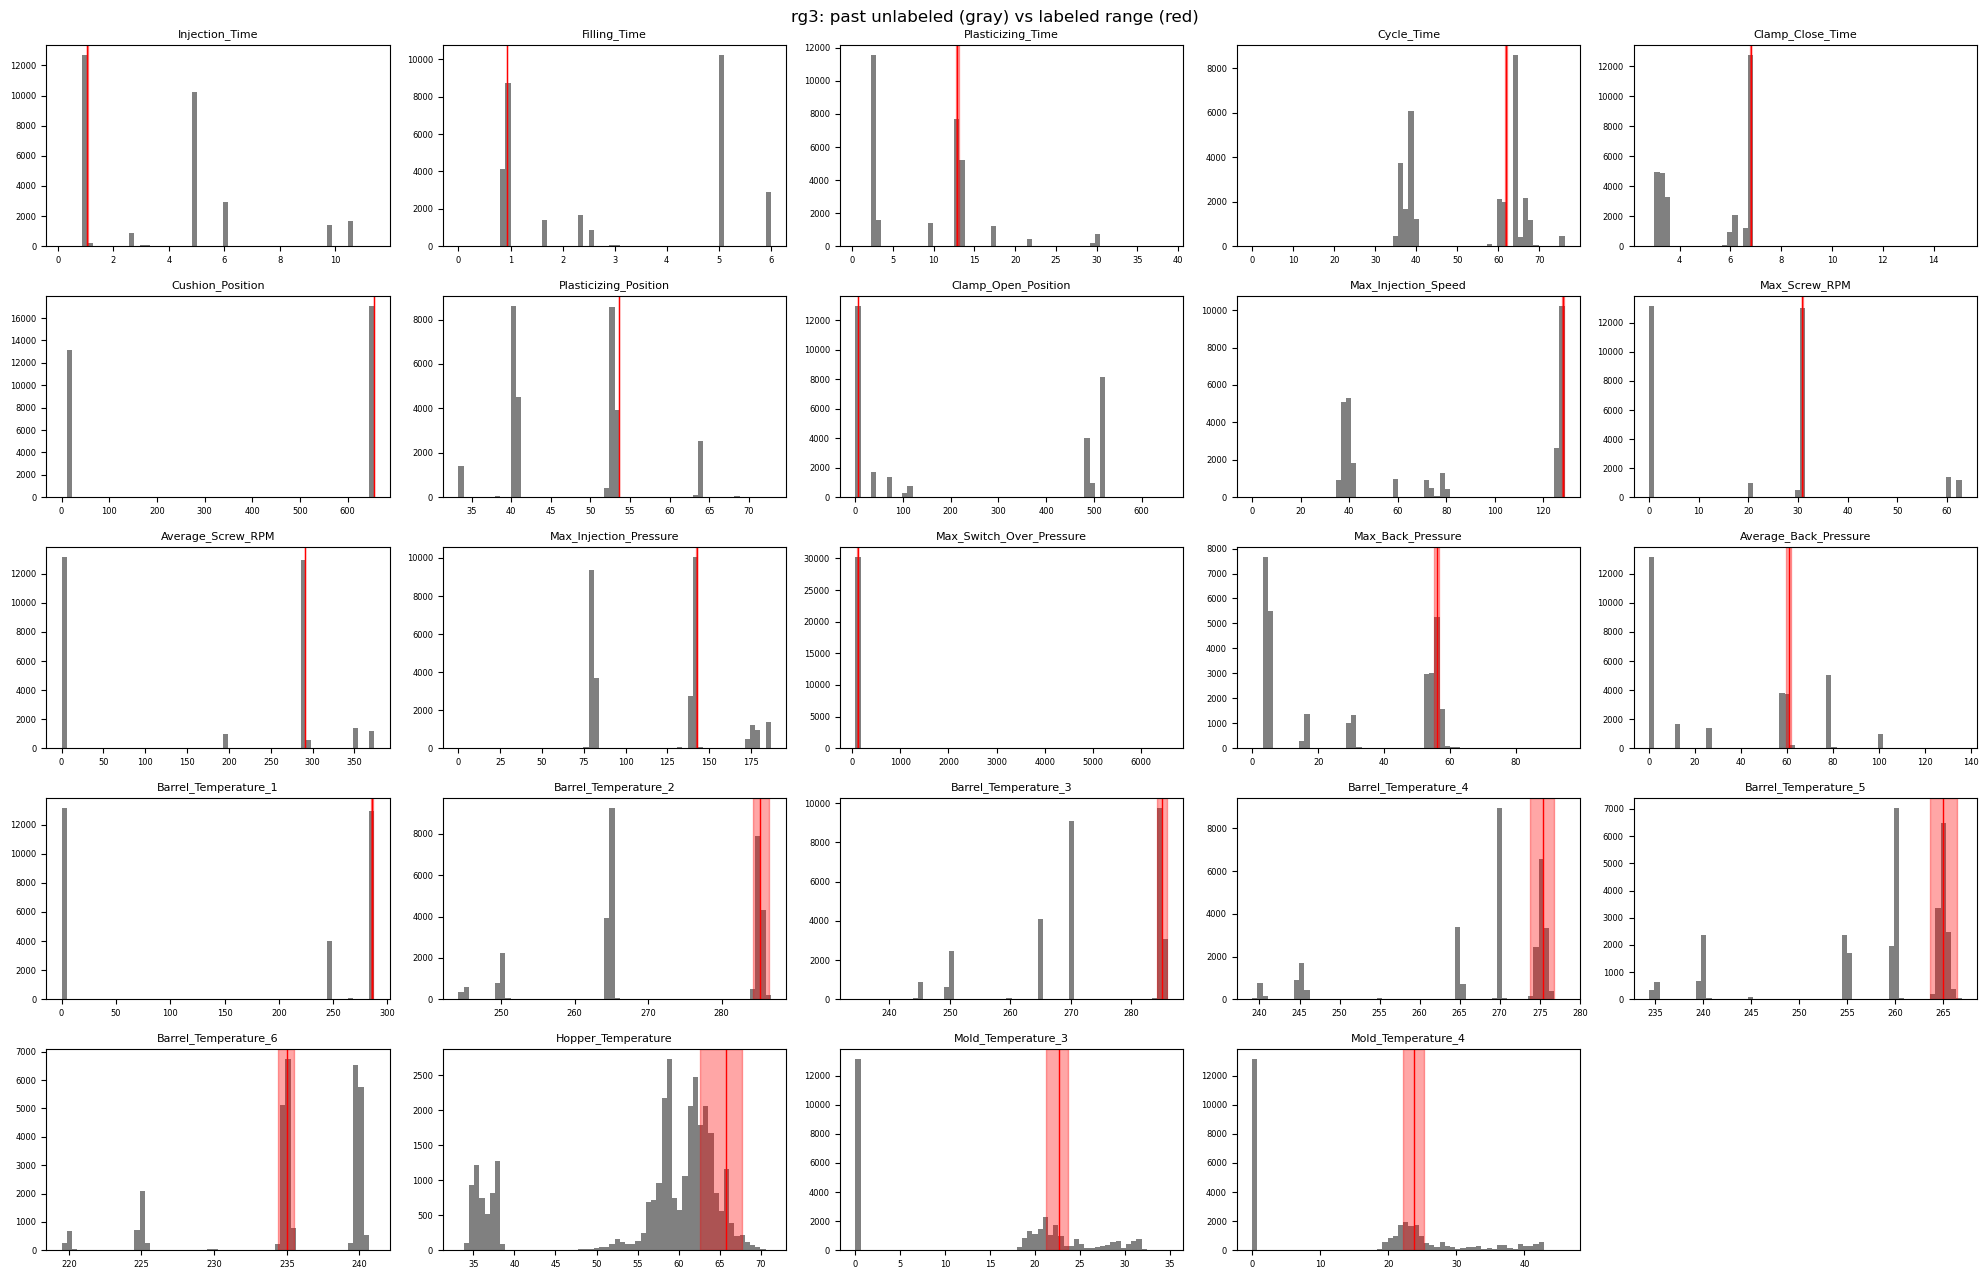

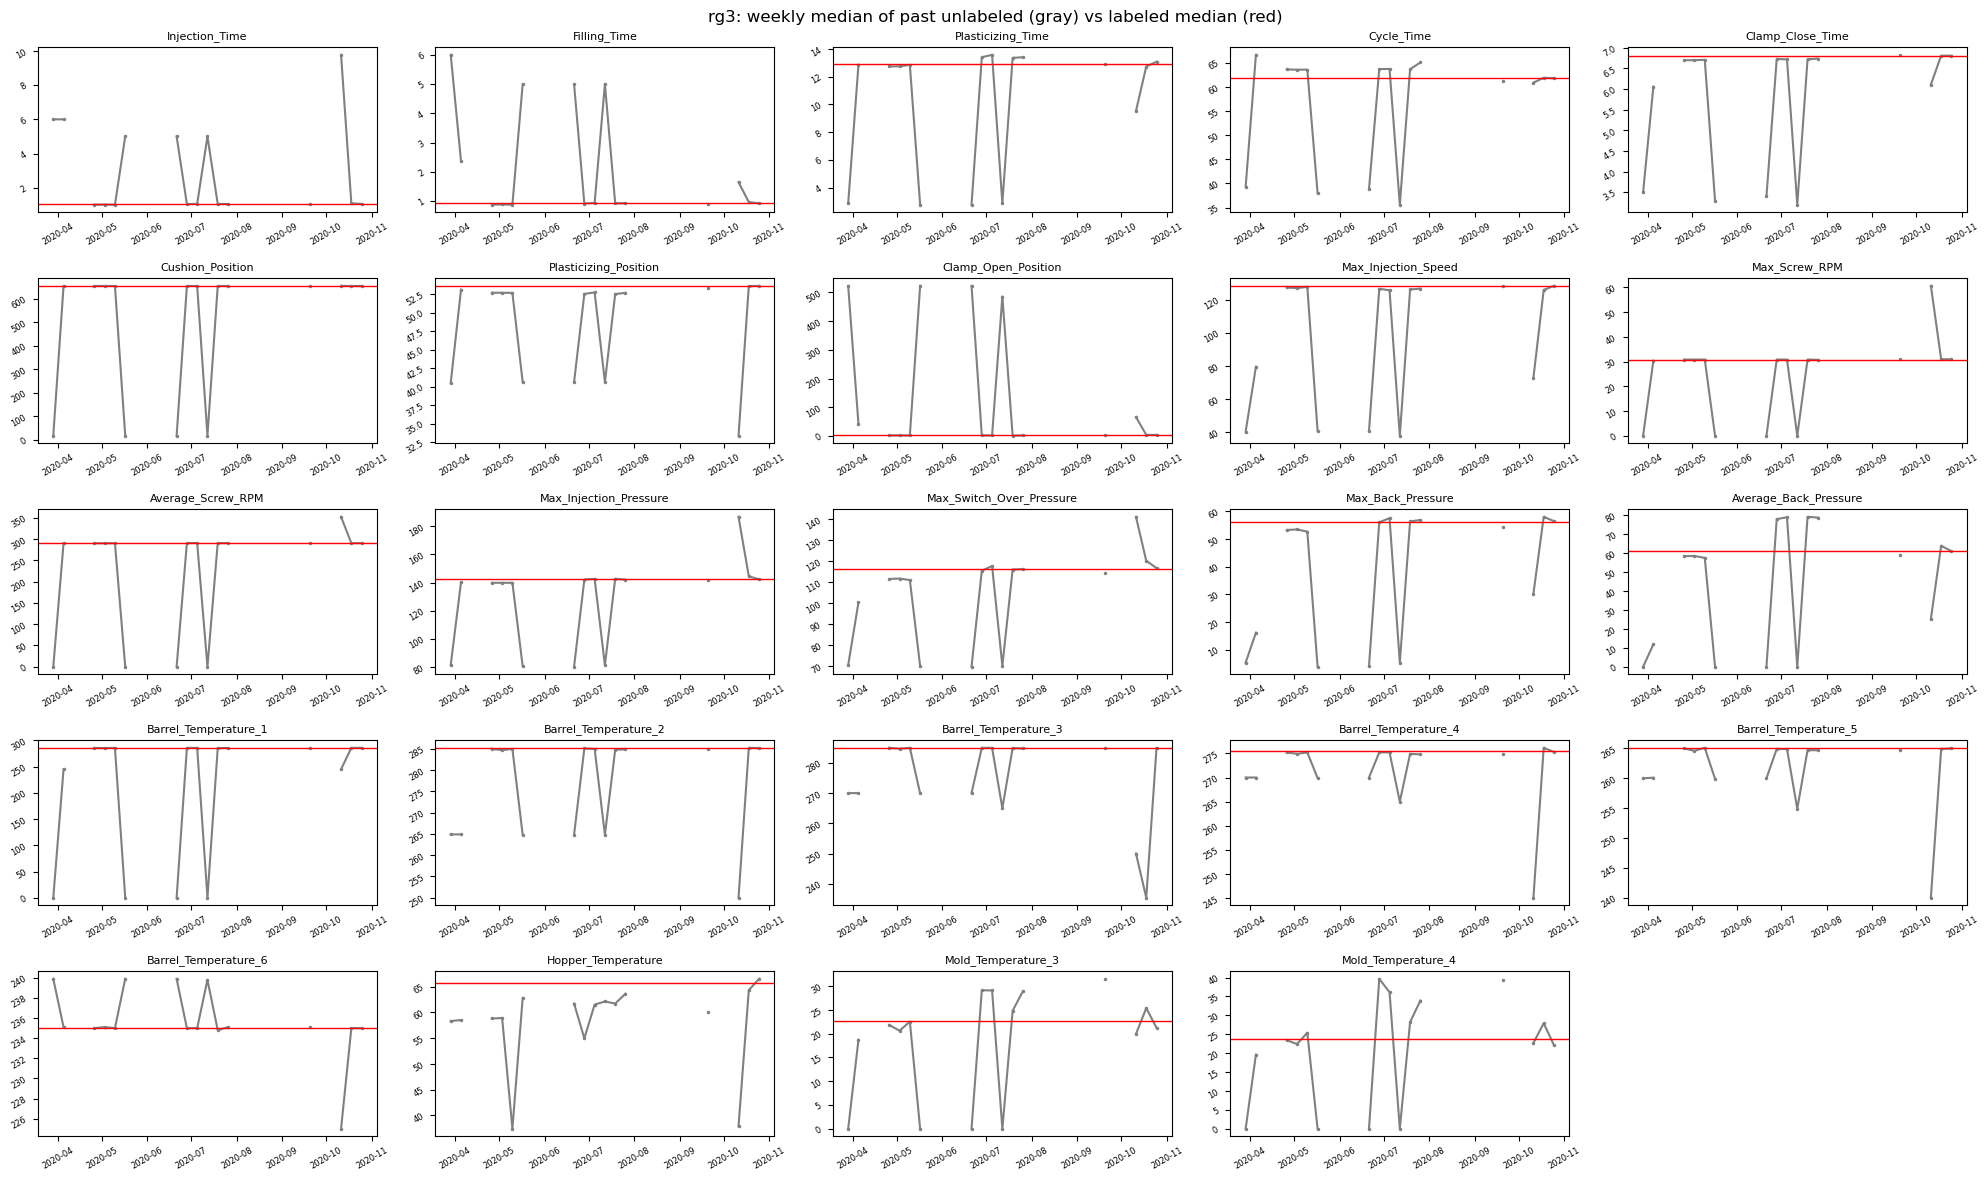


저장 위치: ./output/var_check/


In [4]:
import numpy as np
import matplotlib.pyplot as plt

BASE   = './data_raw_extracted/'          # 추출 파일 위치
OUT_VC = './output/var_check/'            # 결과 저장 위치
os.makedirs(OUT_VC, exist_ok=True)

FEATS = list(pd.read_csv('./data_contest/moldset_unlabeled_cn7.csv', index_col=0, nrows=1).columns)  # 대회 24개 변수

def classify(p_near, p_mid):
    if p_near >= 0.9:  return '차이 없음'
    if p_mid  <  0.05: return '뚝 끊김(설정형) 후보'
    return '서서히 변함 후보'

for mold in ['cn7', 'rg3']:
    n_contest = len(pd.read_csv(f'./data_contest/moldset_labeled_{mold}.csv', index_col=0))  # 대회 라벨 범위 행 수
    L = pd.read_csv(f'{BASE}labeled_{mold}_raw.csv', low_memory=False).iloc[:n_contest]
    U = pd.read_csv(f'{BASE}unlabeled_{mold}_raw.csv', low_memory=False)
    t0 = pd.to_datetime(L['TimeStamp']).min()
    U['t'] = pd.to_datetime(U['TimeStamp'])
    P = U[U['t'] < t0]                               # 라벨 기간 시작 전 비라벨만

    rows = []
    for c in FEATS:
        med, sd = L[c].median(), L[c].std()
        tol = max(5*sd if sd==sd else 0, 0.02*abs(med), 1e-6)   # 라벨 기준 "가까움" 허용폭
        d = (P[c] - med).abs()
        p_near, p_far = (d <= tol).mean(), (d > 10*tol).mean()
        p_mid = 1 - p_near - p_far                    # 가까움과 아주 멂 사이 비율
        rows.append(dict(변수=c, 라벨_최소=L[c].min(), 라벨_중앙=med, 라벨_최대=L[c].max(),
                         비라벨_5=P[c].quantile(.05), 비라벨_중앙=P[c].median(), 비라벨_95=P[c].quantile(.95),
                         가까움=round(p_near,3), 중간=round(p_mid,3), 아주멂=round(p_far,3),
                         분류힌트=classify(p_near, p_mid)))
    T = pd.DataFrame(rows)
    T.to_csv(f'{OUT_VC}var_check_{mold}.csv', index=False, encoding='utf-8-sig')
    print(f'\n===== {mold}: 라벨 {len(L)}행 / 과거 비라벨 {len(P)}행 ({P.t.min():%Y-%m-%d} ~ {P.t.max():%Y-%m-%d})')
    print(T[['변수','라벨_중앙','비라벨_중앙','가까움','중간','아주멂','분류힌트']].to_string(index=False))

    n = len(FEATS); cols = 5; r = int(np.ceil(n/cols))
    # 그래프 1: 분포 (회색=과거 비라벨, 빨강=라벨 범위)
    fig, axes = plt.subplots(r, cols, figsize=(cols*4, r*2.6))
    for ax, c in zip(axes.ravel(), FEATS):
        ax.hist(P[c].dropna(), bins=60, color='gray')
        ax.axvspan(L[c].min(), L[c].max() if L[c].max()>L[c].min() else L[c].min()+1e-9, color='red', alpha=.35)
        ax.axvline(L[c].median(), color='red', lw=1)
        ax.set_title(c, fontsize=8); ax.tick_params(labelsize=6)
    for ax in axes.ravel()[n:]: ax.axis('off')
    fig.suptitle(f'{mold}: past unlabeled (gray) vs labeled range (red)'); fig.tight_layout()
    fig.savefig(f'{OUT_VC}hist_{mold}.png', dpi=110); plt.show(); plt.close(fig)

    # 그래프 2: 주간 중앙값 추이 (서서히 변하는지)
    W = P.set_index('t')[FEATS].resample('W').median()
    fig, axes = plt.subplots(r, cols, figsize=(cols*4, r*2.4))
    for ax, c in zip(axes.ravel(), FEATS):
        ax.plot(W.index, W[c], '.-', ms=3, color='gray')
        ax.axhline(L[c].median(), color='red', lw=1)
        ax.set_title(c, fontsize=8); ax.tick_params(labelsize=6, rotation=30)
    for ax in axes.ravel()[n:]: ax.axis('off')
    fig.suptitle(f'{mold}: weekly median of past unlabeled (gray) vs labeled median (red)'); fig.tight_layout()
    fig.savefig(f'{OUT_VC}trend_{mold}.png', dpi=110); plt.show(); plt.close(fig)

print('\n저장 위치:', OUT_VC)

# 2.공통 설정과 함수

- 전처리, 이상점수, 모델, 나누기, 기준선, 지표를 함수로 정의. 실행은 3번부터.

### 2-1. 설정

In [5]:
import os, json, warnings
import numpy as np
import pandas as pd
import joblib
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, confusion_matrix
warnings.filterwarnings('ignore')

RAW = './data_raw_extracted/'     # 원본 추출 파일 (labeled_full_*, labeled_*, unlabeled_*)
CON = './data_contest/'           # 대회 파일 (moldset_*)
OUT = './output/common/'          # 공통 산출물 저장 위치
SEED = 42
MOLDS = ['cn7', 'rg3']

SEG_GAP = pd.Timedelta('10min')     # 2. 연속 기록 구간: 10분 넘게 끊기면 새 구간
BUNDLE_GAP = pd.Timedelta('60min')  # ④ rg3 묶음: 1시간 미만 끊김만 합침
FPR_LEVELS = [0.005, 0.01, 0.02, 0.05]  # ③ 헛경보 허용 비율 (0.5%는 참고)
REP_LEVEL = 0.02                        # ③ 대표값 2%
N_BOOT = 1000
CN7_BLOCK = pd.Timedelta('1h')          # ⑤ cn7 다시 뽑기 단위

def _read(path):
    d = pd.read_csv(path, low_memory=False)
    d.columns = [c.replace('\ufeff', '') for c in d.columns]
    return d

# 대회 24개 변수 (값이 전부 같은 변수는 [1]에서 데이터로 판단해 제거)
FEATS_24 = list(pd.read_csv(CON + 'moldset_unlabeled_cn7.csv', index_col=0, nrows=1).columns)

### 2-2. 라벨 전처리

In [6]:
def contest_rows(mold):
    """대회 라벨 범위 = labeled_{mold}_raw.csv의 앞 N행 (N = 대회 라벨 파일 행 수, _id 일치 확인함)"""
    n = len(pd.read_csv(f'{CON}moldset_labeled_{mold}.csv', index_col=0))
    return _read(f'{RAW}labeled_{mold}_raw.csv').iloc[:n]

def build_labeled(mold):
    """원본 라벨(전체 기간) → 사출 단위 1행. 반환: (사출 표, 정보 dict)"""
    d = _read(f'{RAW}labeled_full_{mold}_raw.csv')
    n0 = len(d)
    d = d.drop_duplicates('_id')                              # ID 중복 제거 (내용까지 동일)
    d['t'] = pd.to_datetime(d['TimeStamp'])
    d['y'] = (d['PassOrFail'].astype(str).str.upper() == 'N').astype(int)   # 불량=1
    d['Reason'] = d['Reason'].fillna('')

    # 좌우(LH/RH) → 같은 시각 1행. 센서는 시각마다 동일(확인함), 하나라도 불량이면 불량
    assert d.groupby('t')[FEATS_24].nunique().max().max() == 1, '같은 시각에 센서 값이 다른 행이 있음'
    g = d.groupby('t').agg(**{c: (c, 'first') for c in FEATS_24},
                           y=('y', 'max'),
                           reason=('Reason', lambda s: '/'.join(sorted({r for r in s if r}))),
                           n_rows=('y', 'size')).reset_index()

    # 초기허용불량 사출 제외 (금형 교체 직후 예열 문제, 공정 불량 아님)
    init = g['reason'].str.contains('초기허용불량')
    g = g[~init].reset_index(drop=True)

    # 기간 표시: 대회 범위 / 미래
    cend = pd.to_datetime(contest_rows(mold)['TimeStamp']).max()
    g['period'] = np.where(g['t'] <= cend, 'contest', 'future')

    # 연속 기록 구간 번호 (모델 입력 아님, 나누기용 꼬리표)
    g = g.sort_values('t').reset_index(drop=True)
    g['seg'] = (g['t'].diff() > SEG_GAP).cumsum()

    # rg3 묶음 번호 (대회 범위만, 1~5)
    g['bundle'] = 0
    c = g['period'] == 'contest'
    g.loc[c, 'bundle'] = (g.loc[c, 't'].diff() > BUNDLE_GAP).cumsum() + 1

    info = dict(raw_rows=n0, dup_removed=n0 - len(d),
                init_shots_removed=int(init.sum()), contest_end=str(cend))
    return g, info

def contest_scaler(mold):
    """대회 형식 단위 = 대회 범위 원본 행(좌우 포함)의 평균·표준편차(ddof=0).
    대회 파일과 최대 오차 1e-3 이하로 일치하는 것 확인함. 모델과 함께 저장."""
    r = contest_rows(mold)
    mu = r[FEATS_24].mean()
    sd = r[FEATS_24].std(ddof=0)
    const = list(sd[sd == 0].index)            # 값이 전부 같은 변수 → 제거
    feats = [c for c in FEATS_24 if c not in const]
    return dict(mean=mu[feats].to_dict(), std=sd[feats].to_dict(), feats=feats, removed_const=const)

def to_contest_units(df, sc):
    """원본 값 → 대회 형식(표준화) 값. 새 원본 데이터에도 같은 기준으로 적용"""
    X = df[sc['feats']].astype(float).copy()
    for c in sc['feats']:
        X[c] = (X[c] - sc['mean'][c]) / sc['std'][c]
    return X

### 2-3. 비라벨 전처리

In [7]:
def build_unlabeled_past(mold):
    """① 각 금형 라벨 기간 시작 전 + 24개 변수 전부 라벨 중앙값 ± max(5σ, 중앙값 2%) 안
    반환: (행 단위 표, 사출 단위 표)  ※ ① 확정값: cn7 532행, rg3 1,613행"""
    L = contest_rows(mold)
    t0 = pd.to_datetime(L['TimeStamp']).min()
    U = _read(f'{RAW}unlabeled_{mold}_raw.csv')
    U['t'] = pd.to_datetime(U['TimeStamp'])
    P = U[U['t'] < t0]                                        # 미래 비라벨은 사용 안 함
    ok = np.ones(len(P), bool)
    for c in FEATS_24:
        med, sd = L[c].median(), L[c].std()
        tol = max(5 * sd if sd == sd else 0, 0.02 * abs(med), 1e-6)
        ok &= ((P[c] - med).abs() <= tol).values
    rows = P[ok].copy()
    shots = rows.groupby('t')[FEATS_24].first().reset_index()  # 좌우 → 사출 1행 (라벨과 같은 단위)
    return rows, shots


### 2-4. 이상 점수
(Isolation Forest)

In [8]:
def fit_iforest(unl_shots, sc):
    """과거 같은 조건 비라벨로 한 번 학습해서 고정. 라벨 사출은 하나도 안 봄"""
    m = IsolationForest(n_estimators=300, random_state=SEED)
    m.fit(to_contest_units(unl_shots, sc).values)
    return m

def anomaly_score(ifm, X):
    """높을수록 평소와 다름 (score_samples의 부호 반대)"""
    return -ifm.score_samples(np.asarray(X))

def make_X(df, sc, ifm=None, hybrid=False):
    """모델 입력: 대회 형식 공정 변수 (+ 하이브리드면 이상점수 1칸)"""
    X = to_contest_units(df, sc)
    if hybrid:
        X['anomaly_score'] = anomaly_score(ifm, X.values)
    return X



### 2-5 모델 정의

In [9]:
#   하이퍼파라미터는 고정 (튜닝하면 후보 수가 늘어나서 ⑤ 비교 규칙과 안 맞음)
#   LR·SVM은 파이프라인 안에서 StandardScaler → 학습 쪽으로만 기준 (⑶ 조건 3)
SIMPLE_RANK = {'LR': 0, 'RF': 1, 'SVM': 2, 'XGB': 2}   # ⑤ 단순한 순서 (기본 < 하이브리드는 별도)

def _new_model(key, y):
    if key == 'LR':
        return make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=5000))
    if key == 'SVM':
        return make_pipeline(StandardScaler(), SVC(kernel='rbf', class_weight='balanced'))
    if key == 'RF':
        return RandomForestClassifier(n_estimators=500, class_weight='balanced',
                                      min_samples_leaf=2, random_state=SEED, n_jobs=-1)
    if key == 'XGB':
        from xgboost import XGBClassifier
        pos = max(int(np.sum(y)), 1)
        return XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                             subsample=0.8, colsample_bytree=0.8,
                             scale_pos_weight=(len(y) - pos) / pos,
                             random_state=SEED, verbosity=0, n_jobs=-1)
    raise ValueError(key)

class Candidate:
    """후보 1개 = 모델 종류 × {기본, 하이브리드}, 또는 비지도 단독('IF')"""
    def __init__(self, key, hybrid=False):
        self.key, self.hybrid = key, hybrid
        self.name = 'IF_only' if key == 'IF' else f"{key}_{'hyb' if hybrid else 'base'}"
        self.simple = (-1, 0) if key == 'IF' else (SIMPLE_RANK[key], int(hybrid))

    def fit(self, X, y):
        if self.key != 'IF':
            self.m = _new_model(self.key, y).fit(X, y)
        return self

    def score(self, X):
        """불량 쪽일수록 큰 점수 (기준선 비교·PR-AUC용)"""
        if self.key == 'IF':
            return X['anomaly_score'].values
        if hasattr(self.m, 'decision_function'):
            return self.m.decision_function(X)
        return self.m.predict_proba(X)[:, 1]

    def cols(self, X):
        """비지도 단독은 이상점수만, 기본은 공정 변수만, 하이브리드는 둘 다"""
        if self.key == 'IF':
            return X[['anomaly_score']]
        return X if self.hybrid else X.drop(columns=['anomaly_score'], errors='ignore')

def all_candidates(keys=('LR', 'SVM', 'RF', 'XGB')):
    c = [Candidate(k, h) for k in keys for h in (False, True)]
    return c + [Candidate('IF')]

### 2-6 데이터 나누기

In [10]:
def rg3_rounds(bundles=(1, 2, 3, 4, 5)):
    """⑤ rg3: 시험지 1개 고정 → 나머지 4개 중 1개 모의고사, 3개 학습 (4번)"""
    out = []
    for test in bundles:
        rest = [b for b in bundles if b != test]
        mocks = [dict(mock=m, train=[b for b in rest if b != m]) for m in rest]
        out.append(dict(test=test, rest=rest, mocks=mocks))
    return out

def cn7_parts(g):
    """② cn7: 10/16 사건 구간, 사건 후 정상, 10/19~20 정상, 불량 시각 목록"""
    c = g[g['period'] == 'contest']
    ev_seg = c.loc[c['y'] == 1, 'seg'].unique()
    assert len(ev_seg) == 1, '대회 범위 불량이 한 구간에 있지 않음'
    s16 = c[c['seg'] == ev_seg[0]].sort_values('t').reset_index(drop=True)
    other = c[c['seg'] != ev_seg[0]].sort_values('t').reset_index(drop=True)   # 10/19~20
    bad_t = list(s16.loc[s16['y'] == 1, 't'])
    post = s16[s16['t'] > bad_t[-1]]
    return dict(s16=s16, other=other, bad_t=bad_t, post=post)

def cn7_cut(parts, k):
    """컷 k(1~13): k번째 불량 직후까지 학습, 그 뒤 10/16 사출이 탐지 대상"""
    s16, bt = parts['s16'], parts['bad_t']
    tr = s16[s16['t'] <= bt[k - 1]]
    te = s16[s16['t'] > bt[k - 1]]
    return tr, te


### 2-7. OOF 기준선

In [11]:
#   학습에 쓴 사출의 점수는 부풀려져서 사용 안 함 → 학습 데이터 안에서 빼고 학습한 점수 사용
def oof_scores_by_group(cand, X, y, groups):
    """rg3: 묶음 단위로 하나씩 빼고 학습 → 뺀 묶음 점수 (모든 사출)"""
    s = pd.Series(np.nan, index=X.index)
    for gv in np.unique(groups):
        te = groups == gv
        if cand.key != 'IF' and y[~te].sum() == 0:
            continue                                    # 학습 쪽 불량 0개면 학습 불가
        m = Candidate(cand.key, cand.hybrid).fit(cand.cols(X[~te]), y[~te])
        s[te] = m.score(cand.cols(X[te]))
    return s

def oof_scores_normal_blocks(cand, X, y, t, n_blocks=5):
    """cn7: 정상 사출을 시간순 블록 n개로 나눠 하나씩 빼고 학습 (불량은 항상 포함)
    반환: 정상 사출의 OOF 점수"""
    order = np.argsort(np.asarray(t))
    normal_idx = [i for i in order if y[i] == 0]
    blocks = np.array_split(np.array(normal_idx), n_blocks)
    s = pd.Series(np.nan, index=X.index)
    for b in blocks:
        if len(b) == 0:
            continue
        keep = np.ones(len(y), bool); keep[b] = False
        m = Candidate(cand.key, cand.hybrid).fit(cand.cols(X[keep]), y[keep])
        s.iloc[b] = m.score(cand.cols(X.iloc[b]))
    return s[y == 0]

def thresholds_from_normal(normal_scores, levels=FPR_LEVELS):
    """③ 정상 OOF 점수의 상위 X% → 기준선 dict {0.02: 값, ...}"""
    v = np.asarray(normal_scores, float); v = v[~np.isnan(v)]
    return {lv: float(np.quantile(v, 1 - lv)) for lv in levels}

### 2-8. 평가 지표

In [12]:
def metrics_at(y, score, thr):
    """기준선 하나에서의 지표. 경보 = 점수 > 기준선"""
    y = np.asarray(y); pred = (np.asarray(score) > thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else np.nan
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) and rec == rec else 0.0
    fpr = fp / (fp + tn) if fp + tn else np.nan
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, precision=prec, recall=rec, f1=f1, fpr=fpr)

def pr_auc(y, score):
    y = np.asarray(y)
    return float(average_precision_score(y, score)) if 0 < y.sum() < len(y) else np.nan

def eval_table(y, score, thr_dict):
    """헛경보 허용 비율별 결과 표 (보고서 8-4) + PR-AUC"""
    rows = [dict(level=lv, threshold=th, **metrics_at(y, score, th)) for lv, th in thr_dict.items()]
    t = pd.DataFrame(rows); t['pr_auc'] = pr_auc(y, score)
    return t

def three_way(score, thr_dict):
    """③ 3단계 판정 (보고서·현장 운영안용): 0.5% 이상=불량 / 0.5~2%=재검사 / 나머지=통과"""
    s = np.asarray(score)
    return np.where(s > thr_dict[0.005], '불량', np.where(s > thr_dict[0.02], '재검사', '통과'))

### 2-9. cn7 조기경보 실험 함수

In [13]:
def cn7_cut_result(parts, k, cand, X_s16, X_other, ifm_train_max=None):
    """컷 k 하나의 결과 1행. k=0은 비지도(이상점수, 기준선=직전 비라벨 최고점)"""
    s16, other, post = parts['s16'], parts['other'], parts['post']
    ys = s16['y'].values
    if k == 0:
        cut_t = s16['t'].min() - pd.Timedelta('1s')
        te = s16.index
        sc_te = X_s16.loc[te, 'anomaly_score'].values
        sc_other = X_other['anomaly_score'].values
        thr = ifm_train_max
    else:
        tr, te_df = cn7_cut(parts, k)
        te = te_df.index; cut_t = parts['bad_t'][k - 1]
        Xtr, ytr = X_s16.loc[tr.index], ys[tr.index]
        m = Candidate(cand.key, cand.hybrid).fit(cand.cols(Xtr), ytr)
        oof = oof_scores_normal_blocks(cand, Xtr, ytr, tr['t'].values)
        thr = float(np.nanmax(oof))                     # ② 정상 OOF 점수의 최고값
        sc_te = m.score(cand.cols(X_s16.loc[te]))
        sc_other = m.score(cand.cols(X_other))
    yt = ys[te]; alarm = sc_te > thr
    in_post = s16.loc[te, 't'].isin(post['t']).values
    ev = ~in_post                                        # 사건 중(컷 이후 ~ 마지막 불량)
    first_any = int(np.argmax(alarm)) + 1 if alarm.any() else None
    first_true = int(np.argmax(alarm & (yt == 1))) + 1 if (alarm & (yt == 1)).any() else None
    n_left = int(yt.sum())
    return dict(cut=k, model=cand.name, seen_bad=k, threshold=thr,
                first_alarm_after=first_any, first_true_alarm_after=first_true,
                left_bad=n_left, caught=int((alarm & (yt == 1)).sum()),
                recall=(alarm & (yt == 1)).sum() / n_left if n_left else np.nan,
                fa_event=int((alarm & ev & (yt == 0)).sum()), n_event_normal=int((ev & (yt == 0)).sum()),
                fa_post=int((alarm & in_post).sum()), n_post=int(in_post.sum()),
                fa_1019=int((sc_other > thr).sum()), n_1019=len(sc_other),
                pr_auc=pr_auc(yt, sc_te),
                _alarm_post=alarm[in_post], _alarm_1019=(sc_other > thr))

### 2-10. rg3 모의고사, 시험지 함수

In [14]:
def rg3_mock_eval(cand, X, y, b, rnd):
    """한 라운드에서 후보 1개의 모의고사 4번 → 예측을 합쳐 PR-AUC 1번 계산.
    F1은 ③ 대표값 2% 기준선(각 모의고사의 학습 묶음 안 묶음 단위 OOF로 정함)"""
    y = np.asarray(y); b = np.asarray(b)
    ys, ss, gs, pred = [], [], [], []
    for mk in rnd['mocks']:
        tr = np.isin(b, mk['train']); mo = b == mk['mock']
        m = Candidate(cand.key, cand.hybrid).fit(cand.cols(X[tr]), y[tr])
        oof = oof_scores_by_group(cand, X[tr], y[tr], b[tr])
        thr = thresholds_from_normal(oof[y[tr] == 0], [REP_LEVEL])[REP_LEVEL]
        s = m.score(cand.cols(X[mo]))
        ys += list(y[mo]); ss += list(s); gs += list(b[mo]); pred += list(s > thr)
    ys, ss, gs, pred = map(np.asarray, (ys, ss, gs, pred))
    tp = int((pred & (ys == 1)).sum()); fp = int((pred & (ys == 0)).sum()); fn = int((~pred & (ys == 1)).sum())
    f1 = 2 * tp / (2 * tp + fp + fn) if tp else 0.0
    return dict(name=cand.name, simple=cand.simple, pr_auc=pr_auc(ys, ss), f1=f1,
                TP=tp, FP=fp, FN=fn, y=ys, score=ss, group=gs)

def rg3_test_eval(cand, X, y, b, rnd):
    """라운드 1등만: 모의고사에 쓴 4묶음 전체로 재학습 → 시험지 1번 채점.
    기준선은 4묶음 안 묶음 단위 OOF로 정하고 시험지엔 적용만 (⑥)"""
    y = np.asarray(y); b = np.asarray(b)
    tr = np.isin(b, rnd['rest']); te = b == rnd['test']
    m = Candidate(cand.key, cand.hybrid).fit(cand.cols(X[tr]), y[tr])
    oof = oof_scores_by_group(cand, X[tr], y[tr], b[tr])
    thr = thresholds_from_normal(oof[y[tr] == 0])
    s = m.score(cand.cols(X[te]))
    return dict(name=cand.name, test=rnd['test'], y=y[te], score=s, thr=thr, table=eval_table(y[te], s, thr))

### 2-11. 블록 다시 뽑기

In [15]:
def boot_diff_rg3(y, s_a, s_b, groups, n=N_BOOT, seed=SEED):
    """⑤ rg3: 합친 모의고사 예측을 묶음 단위로 다시 뽑아 PR-AUC 차이(a-b)의 95% 범위"""
    rng = np.random.default_rng(seed); y = np.asarray(y); g = np.asarray(groups)
    ug = np.unique(g); idx = {u: np.where(g == u)[0] for u in ug}
    d = []
    for _ in range(n):
        pick = np.concatenate([idx[u] for u in rng.choice(ug, len(ug), replace=True)])
        if 0 < y[pick].sum() < len(pick):
            d.append(pr_auc(y[pick], s_a[pick]) - pr_auc(y[pick], s_b[pick]))
    lo, hi = np.percentile(d, [2.5, 97.5])
    return dict(diff=pr_auc(y, s_a) - pr_auc(y, s_b), lo=lo, hi=hi, similar=bool(lo <= 0 <= hi), n_valid=len(d))

def hour_blocks(t):
    t = pd.to_datetime(pd.Series(t)).reset_index(drop=True)
    return ((t - t.min()) // CN7_BLOCK).astype(int).values

def boot_diff_cn7(res_a, res_b, blk_post, blk_1019, cuts=range(1, 6), n=N_BOOT, seed=SEED):
    """⑤ cn7: 헛경보 구간(사건 후 / 10/19~20)을 1시간 블록 단위로 다시 뽑아
    컷 1~5 평균 오탐률 차이(a-b)의 95% 범위. res_* = {컷: cn7_cut_result 결과}"""
    rng = np.random.default_rng(seed)
    def fpr(res, ip, io):
        return np.mean([(res[k]['_alarm_post'][ip].mean() + res[k]['_alarm_1019'][io].mean()) / 2 for k in cuts])
    ap, ao = np.arange(len(blk_post)), np.arange(len(blk_1019))
    up, uo = np.unique(blk_post), np.unique(blk_1019)
    d = []
    for _ in range(n):
        ip = np.concatenate([ap[blk_post == u] for u in rng.choice(up, len(up))])
        io = np.concatenate([ao[blk_1019 == u] for u in rng.choice(uo, len(uo))])
        d.append(fpr(res_a, ip, io) - fpr(res_b, ip, io))
    lo, hi = np.percentile(d, [2.5, 97.5])
    return dict(diff=fpr(res_a, ap, ao) - fpr(res_b, ap, ao), lo=lo, hi=hi, similar=bool(lo <= 0 <= hi))

def boot_ci(y, score_or_pred, groups, stat, n=N_BOOT, seed=SEED):
    """⑦ 점수 범위(95%): rg3=묶음, cn7=1시간 블록 단위로 다시 뽑아 stat(y, s) 계산"""
    rng = np.random.default_rng(seed); y = np.asarray(y); s = np.asarray(score_or_pred); g = np.asarray(groups)
    ug = np.unique(g); idx = {u: np.where(g == u)[0] for u in ug}; v = []
    for _ in range(n):
        pick = np.concatenate([idx[u] for u in rng.choice(ug, len(ug))])
        r = stat(y[pick], s[pick])
        if r == r: v.append(r)
    return np.percentile(v, [2.5, 97.5])

### 2-12. 생성, 저장, 점검 함수

In [16]:
def build_all(save=True):
    os.makedirs(OUT, exist_ok=True)
    data = {}
    for mold in MOLDS:
        g, info = build_labeled(mold)
        sc = contest_scaler(mold)
        rows, shots = build_unlabeled_past(mold)
        ifm = fit_iforest(shots, sc)
        X_unl = make_X(shots, sc, ifm, hybrid=True)
        if_max = float(X_unl['anomaly_score'].max())        # ② 0단계 기준선
        g = pd.concat([g, make_X(g, sc, ifm, hybrid=True)[['anomaly_score']]], axis=1)
        data[mold] = dict(g=g, sc=sc, ifm=ifm, if_train_max=if_max, unl_rows=len(rows), unl_shots=len(shots))
        if save:
            g.to_csv(f'{OUT}labeled_{mold}.csv', index=False, encoding='utf-8-sig')
            json.dump(sc, open(f'{OUT}scaler_{mold}.json', 'w'), ensure_ascii=False, indent=1)
            joblib.dump(dict(model=ifm, feats=sc['feats'], train_max=if_max), f'{OUT}iforest_{mold}.joblib')

        # ---- 점검: 문서에 적힌 숫자와 맞는지 ----
        c = g[g['period'] == 'contest']; f = g[g['period'] == 'future']
        print(f'\n===== {mold} =====')
        print(f"원본 {info['raw_rows']}행 → ID 중복 {info['dup_removed']}행 제거, 초기허용불량 {info['init_shots_removed']}사출 제외")
        print(f"제거한 상수 변수: {sc['removed_const']} → 입력 변수 {len(sc['feats'])}개")
        print(f"대회 범위: {len(c)}사출, 불량 {c.y.sum()} / 미래: {len(f)}사출, 불량 {f.y.sum()}")
        print(f"과거 같은 조건 비라벨: {len(rows)}행 ({len(shots)}사출), 이상점수 학습 최고 {if_max:.4f}")
        print('대회 범위 연속 구간(10분):')
        print(c.groupby('seg').agg(start=('t', 'min'), end=('t', 'max'), n=('y', 'size'), bad=('y', 'sum')).to_string())
        if mold == 'rg3':
            print('묶음(1시간):')
            print(c.groupby('bundle').agg(start=('t', 'min'), end=('t', 'max'), n=('y', 'size'), bad=('y', 'sum')).to_string())
        else:
            p = cn7_parts(g)
            print(f"10/16 사건 구간 {len(p['s16'])}사출, 불량 {len(p['bad_t'])}개, 사건 후 정상 {len(p['post'])}, 10/19~20 {len(p['other'])}사출")
        print('불량 종류(해석용):', g.loc[g.y == 1].groupby(['period', 'reason']).size().to_dict())
    return data

# 3. 데이터 전처리 실행

- 사출 단위로 정리
- 과거 같은 운전 조건 비라벨로 이상점수 모델을 학습해 고정

### 3-1. 전처리 실행과 점검

In [17]:
D = build_all()


===== cn7 =====
원본 6736행 → ID 중복 2762행 제거, 초기허용불량 5사출 제외
제거한 상수 변수: ['Clamp_Open_Position'] → 입력 변수 23개
대회 범위: 606사출, 불량 14 / 미래: 1384사출, 불량 1
과거 같은 조건 비라벨: 532행 (446사출), 이상점수 학습 최고 0.7027
대회 범위 연속 구간(10분):
                  start                 end    n  bad
seg                                                  
0   2020-10-16 04:57:47 2020-10-16 08:05:18  188   14
1   2020-10-19 23:24:46 2020-10-20 06:20:14  418    0
10/16 사건 구간 188사출, 불량 14개, 사건 후 정상 127, 10/19~20 418사출
불량 종류(해석용): {('contest', '가스'): 11, ('contest', '가스/미성형'): 2, ('contest', '미성형'): 1, ('future', '미성형'): 1}

===== rg3 =====
원본 1256행 → ID 중복 0행 제거, 초기허용불량 0사출 제외
제거한 상수 변수: ['Clamp_Open_Position'] → 입력 변수 23개
대회 범위: 591사출, 불량 25 / 미래: 38사출, 불량 7
과거 같은 조건 비라벨: 1613행 (807사출), 이상점수 학습 최고 0.6651
대회 범위 연속 구간(10분):
                  start                 end    n  bad
seg                                                  
0   2020-10-21 00:16:26 2020-10-21 00:57:37   41    0
1   2020-10-22 00:24:05 2020-10-22 01:28:56   64

### 3-2. 경보 기준선 방식 근거 확인

In [18]:
# ② 근거: 컷1 RF, 학습 점수 기준선 vs 분할(OOF) 기준선의 10/19~20 헛경보
d = D['cn7']; p = cn7_parts(d['g'])
X16 = make_X(p['s16'], d['sc'], d['ifm'], hybrid=False)
Xo  = make_X(p['other'], d['sc'], d['ifm'], hybrid=False)
tr, _ = cn7_cut(p, 1)
Xtr, ytr = X16.loc[tr.index], tr['y'].values

rf = Candidate('RF').fit(Xtr, ytr)
thr_train = rf.score(Xtr[ytr == 0]).max()                                    # 학습 점수 기준선
thr_oof   = np.nanmax(oof_scores_normal_blocks(Candidate('RF'), Xtr, ytr, tr['t'].values))  # 분할 기준선
s_o = rf.score(Xo)
print('학습 점수 기준선:', (s_o > thr_train).sum(), '/', len(Xo))
print('분할 기준선   :', (s_o > thr_oof).sum(), '/', len(Xo))


학습 점수 기준선: 316 / 418
분할 기준선   : 70 / 418


# 4. 모델 비교(대회 범위)

- rg3는 5묶음 중 시험지 1개를 빼고 모의고사 4번
- cn7은 불량 0~13개를 본 시점별 조기경보 실험.

### 4-1. 비교 후보 설정

In [19]:
KEYS   = ('LR', 'SVM', 'RF', 'XGB')
USE_IF = True
WHO    = 'me'

RES = './output/compare/'
os.makedirs(RES, exist_ok=True)
CANDS = [Candidate(k, h) for k in KEYS for h in (False, True)]   # 기본 / 하이브리드
if USE_IF:
    CANDS.append(Candidate('IF'))
print('후보:', [c.name for c in CANDS])


후보: ['LR_base', 'LR_hyb', 'SVM_base', 'SVM_hyb', 'RF_base', 'RF_hyb', 'XGB_base', 'XGB_hyb', 'IF_only']


### 4-2. rg3 모의고사 비교

In [20]:
d = D['rg3']
c = d['g'][d['g']['period'] == 'contest'].reset_index(drop=True)
X = make_X(c, d['sc'], d['ifm'], hybrid=True)
y, b = c['y'].values, c['bundle'].values

rows, preds = [], []
for rnd in rg3_rounds():
    # 모의고사 4번을 합친 순서 (후보끼리 같은 사출끼리 비교하기 위한 위치 번호)
    order = np.concatenate([np.where(b == mk['mock'])[0] for mk in rnd['mocks']])
    for cand in CANDS:
        r = rg3_mock_eval(cand, X, y, b, rnd)
        rows.append(dict(who=WHO, test_bundle=rnd['test'], cand=r['name'],
                         pr_auc=r['pr_auc'], f1=r['f1'], TP=r['TP'], FP=r['FP'], FN=r['FN']))
        preds.append(pd.DataFrame(dict(test_bundle=rnd['test'], cand=r['name'], row=order,
                                       y=r['y'], score=r['score'], bundle=r['group'])))
        print(f"시험지 묶음{rnd['test']} | {r['name']:9s} | 모의고사 PR-AUC {r['pr_auc']:.3f} | F1 {r['f1']:.3f}")

rg3_mock = pd.DataFrame(rows)
rg3_mock.to_csv(f'{RES}rg3_mock_{WHO}.csv', index=False, encoding='utf-8-sig')
pd.concat(preds).to_csv(f'{RES}rg3_mock_pred_{WHO}.csv', index=False, encoding='utf-8-sig')
print('\n저장:', f'{RES}rg3_mock_{WHO}.csv', f'{RES}rg3_mock_pred_{WHO}.csv')

시험지 묶음1 | LR_base   | 모의고사 PR-AUC 0.042 | F1 0.051
시험지 묶음1 | LR_hyb    | 모의고사 PR-AUC 0.042 | F1 0.056
시험지 묶음1 | SVM_base  | 모의고사 PR-AUC 0.043 | F1 0.034
시험지 묶음1 | SVM_hyb   | 모의고사 PR-AUC 0.043 | F1 0.017
시험지 묶음1 | RF_base   | 모의고사 PR-AUC 0.043 | F1 0.040
시험지 묶음1 | RF_hyb    | 모의고사 PR-AUC 0.052 | F1 0.033
시험지 묶음1 | XGB_base  | 모의고사 PR-AUC 0.050 | F1 0.051
시험지 묶음1 | XGB_hyb   | 모의고사 PR-AUC 0.050 | F1 0.027
시험지 묶음1 | IF_only   | 모의고사 PR-AUC 0.038 | F1 0.061
시험지 묶음2 | LR_base   | 모의고사 PR-AUC 0.047 | F1 0.000
시험지 묶음2 | LR_hyb    | 모의고사 PR-AUC 0.050 | F1 0.000
시험지 묶음2 | SVM_base  | 모의고사 PR-AUC 0.051 | F1 0.069
시험지 묶음2 | SVM_hyb   | 모의고사 PR-AUC 0.051 | F1 0.073
시험지 묶음2 | RF_base   | 모의고사 PR-AUC 0.039 | F1 0.000
시험지 묶음2 | RF_hyb    | 모의고사 PR-AUC 0.043 | F1 0.000
시험지 묶음2 | XGB_base  | 모의고사 PR-AUC 0.039 | F1 0.000
시험지 묶음2 | XGB_hyb   | 모의고사 PR-AUC 0.046 | F1 0.000
시험지 묶음2 | IF_only   | 모의고사 PR-AUC 0.037 | F1 0.065
시험지 묶음3 | LR_base   | 모의고사 PR-AUC 0.028 | F1 0.000
시험지 묶음3 | LR_hyb    | 모의고사 PR-A

### 4-3 cn7 조기경보 실험

In [21]:
d = D['cn7']
p = cn7_parts(d['g'])
X16 = make_X(p['s16'], d['sc'], d['ifm'], hybrid=True)    # 10/16 사건 구간
Xo  = make_X(p['other'], d['sc'], d['ifm'], hybrid=True)  # 10/19~20 (학습 안 함, 헛경보 확인용)
post_mask = p['s16']['t'].isin(p['post']['t']).values      # 사건 후 정상 127사출

def cn7_if_cut(k):
    """비지도 단독: 모델은 직전 비라벨로 고정, 기준선 = 직전 비라벨 최고 이상점수 (②).
    컷 k 이후 10/16 사출이 탐지 대상 (k=0이면 10/16 전체)"""
    s16 = p['s16']
    cut_t = s16['t'].min() - pd.Timedelta('1s') if k == 0 else p['bad_t'][k - 1]
    te = (s16['t'] > cut_t).values
    thr = d['if_train_max']
    sc_te = X16['anomaly_score'].values[te]; yt = s16['y'].values[te]
    alarm = sc_te > thr; inp = post_mask[te]; ev = ~inp
    a1019 = Xo['anomaly_score'].values > thr
    n_left = int(yt.sum())
    return dict(cut=k, model='IF_only', seen_bad=k, threshold=thr,
                first_alarm_after=int(np.argmax(alarm)) + 1 if alarm.any() else None,
                first_true_alarm_after=int(np.argmax(alarm & (yt == 1))) + 1 if (alarm & (yt == 1)).any() else None,
                left_bad=n_left, caught=int((alarm & (yt == 1)).sum()),
                recall=(alarm & (yt == 1)).sum() / n_left if n_left else np.nan,
                fa_event=int((alarm & ev & (yt == 0)).sum()), n_event_normal=int((ev & (yt == 0)).sum()),
                fa_post=int((alarm & inp).sum()), n_post=int(inp.sum()),
                fa_1019=int(a1019.sum()), n_1019=len(a1019),
                pr_auc=pr_auc(yt, sc_te),
                _alarm_post=alarm[inp], _alarm_1019=a1019)

rows, alarms = [], []
for cand in CANDS:
    for k in range(0, 14):
        if cand.key == 'IF':
            r = cn7_if_cut(k)
        elif k == 0:
            continue                       # 컷 0(불량 0개)은 비지도만
        else:
            r = cn7_cut_result(p, k, cand, X16, Xo)
        rows.append(dict(who=WHO, **{kk: v for kk, v in r.items() if not kk.startswith('_')}))
        alarms.append(pd.DataFrame(dict(cand=r['model'], cut=k, where='post',
                                        i=np.arange(len(r['_alarm_post'])), alarm=r['_alarm_post'])))
        alarms.append(pd.DataFrame(dict(cand=r['model'], cut=k, where='1019',
                                        i=np.arange(len(r['_alarm_1019'])), alarm=r['_alarm_1019'])))
        print(f"{r['model']:9s} 컷{k:2d} | 남은 불량 {r['left_bad']:2d} 중 {r['caught']:2d} | "
              f"사건 후 헛경보 {r['fa_post']}/{r['n_post']} | 10/19~20 헛경보 {r['fa_1019']}/{r['n_1019']}")

cn7_cut_tbl = pd.DataFrame(rows)
cn7_cut_tbl.to_csv(f'{RES}cn7_cut_{WHO}.csv', index=False, encoding='utf-8-sig')
pd.concat(alarms).to_csv(f'{RES}cn7_cut_alarm_{WHO}.csv', index=False, encoding='utf-8-sig')
print('\n저장:', f'{RES}cn7_cut_{WHO}.csv', f'{RES}cn7_cut_alarm_{WHO}.csv')

LR_base   컷 1 | 남은 불량 13 중  3 | 사건 후 헛경보 7/127 | 10/19~20 헛경보 191/418
LR_base   컷 2 | 남은 불량 12 중  2 | 사건 후 헛경보 17/127 | 10/19~20 헛경보 0/418
LR_base   컷 3 | 남은 불량 11 중  0 | 사건 후 헛경보 4/127 | 10/19~20 헛경보 0/418
LR_base   컷 4 | 남은 불량 10 중  0 | 사건 후 헛경보 3/127 | 10/19~20 헛경보 2/418
LR_base   컷 5 | 남은 불량  9 중  0 | 사건 후 헛경보 3/127 | 10/19~20 헛경보 22/418
LR_base   컷 6 | 남은 불량  8 중  0 | 사건 후 헛경보 2/127 | 10/19~20 헛경보 3/418
LR_base   컷 7 | 남은 불량  7 중  0 | 사건 후 헛경보 6/127 | 10/19~20 헛경보 3/418
LR_base   컷 8 | 남은 불량  6 중  0 | 사건 후 헛경보 16/127 | 10/19~20 헛경보 4/418
LR_base   컷 9 | 남은 불량  5 중  0 | 사건 후 헛경보 4/127 | 10/19~20 헛경보 30/418
LR_base   컷10 | 남은 불량  4 중  0 | 사건 후 헛경보 4/127 | 10/19~20 헛경보 4/418
LR_base   컷11 | 남은 불량  3 중  0 | 사건 후 헛경보 4/127 | 10/19~20 헛경보 5/418
LR_base   컷12 | 남은 불량  2 중  0 | 사건 후 헛경보 3/127 | 10/19~20 헛경보 6/418
LR_base   컷13 | 남은 불량  1 중  0 | 사건 후 헛경보 3/127 | 10/19~20 헛경보 11/418
LR_hyb    컷 1 | 남은 불량 13 중  3 | 사건 후 헛경보 6/127 | 10/19~20 헛경보 176/418
LR_hyb    컷 2 | 남은 불량 12 중  2 | 사건 후 헛경

# 5. 모델 선택

- 실행 전 확정 ⑤ 규칙으로 후보를 고름
- 시험지는 라운드 1등만 한 번 채점


### 5.1 비교 결과 불러오기

In [22]:
RG3_MOCK  = pd.read_csv(f'{RES}rg3_mock_{WHO}.csv')
RG3_PRED  = pd.read_csv(f'{RES}rg3_mock_pred_{WHO}.csv')
CN7_CUT   = pd.read_csv(f'{RES}cn7_cut_{WHO}.csv')
CN7_ALARM = pd.read_csv(f'{RES}cn7_cut_alarm_{WHO}.csv')
CN7_ALARM['where'] = CN7_ALARM['where'].astype(str)

def simple_of(name):
    """⑤ 단순한 순서 (작을수록 단순). IF_only는 가장 단순"""
    if name == 'IF_only':
        return (-1, 0)
    k, h = name.split('_')
    return (SIMPLE_RANK[k], int(h == 'hyb'))

def cand_of(name):
    if name == 'IF_only':
        return Candidate('IF')
    k, h = name.split('_')
    return Candidate(k, h == 'hyb')

print('rg3 후보:', sorted(RG3_MOCK['cand'].unique()))
print('cn7 후보:', sorted(CN7_CUT['model'].unique()))


rg3 후보: ['IF_only', 'LR_base', 'LR_hyb', 'RF_base', 'RF_hyb', 'SVM_base', 'SVM_hyb', 'XGB_base', 'XGB_hyb']
cn7 후보: ['IF_only', 'LR_base', 'LR_hyb', 'RF_base', 'RF_hyb', 'SVM_base', 'SVM_hyb', 'XGB_base', 'XGB_hyb']


### 5-2. rg3 라운드 1등 선정

In [23]:
def pick_rg3_round(tb):
    m = RG3_MOCK[RG3_MOCK['test_bundle'] == tb].copy().reset_index(drop=True)
    P = RG3_PRED[RG3_PRED['test_bundle'] == tb]
    best = m.loc[m['pr_auc'].idxmax(), 'cand']
    pb = P[P['cand'] == best].sort_values('row')
    m['diff_lo'] = np.nan; m['diff_hi'] = np.nan; m['similar'] = False
    for i, cn in enumerate(m['cand']):
        if cn == best:
            m.loc[i, 'similar'] = True
            continue
        pc = P[P['cand'] == cn].sort_values('row')
        r = boot_diff_rg3(pb['y'].values, pb['score'].values, pc['score'].values, pb['bundle'].values)
        m.loc[i, ['diff_lo', 'diff_hi', 'similar']] = [r['lo'], r['hi'], r['similar']]
    S = m[m['similar']]                       # 1등과 비슷한 후보들만 다음 단계로
    S = S[S['f1'] == S['f1'].max()].copy()    # F1이 가장 높은 후보 (값이 같으면 다음 단계)
    S['s0'] = S['cand'].map(lambda x: simple_of(x)[0])
    S['s1'] = S['cand'].map(lambda x: simple_of(x)[1])
    win = S.sort_values(['s0', 's1', 'pr_auc'], ascending=[True, True, False]).iloc[0]['cand']
    return win, m.sort_values('pr_auc', ascending=False)

RG3_WIN = {}
for rnd in rg3_rounds():
    win, tbl = pick_rg3_round(rnd['test'])
    RG3_WIN[rnd['test']] = win
    print(f"\n=== 시험지 묶음{rnd['test']} 라운드 → 1등: {win}")
    print(tbl[['cand', 'pr_auc', 'f1', 'diff_lo', 'diff_hi', 'similar']].to_string(index=False))
pd.Series(RG3_WIN, name='winner').to_csv(f'{RES}rg3_round_winners.csv', encoding='utf-8-sig')


=== 시험지 묶음1 라운드 → 1등: XGB_base
    cand   pr_auc       f1   diff_lo  diff_hi  similar
  RF_hyb 0.051840 0.032787       NaN      NaN     True
 XGB_hyb 0.049946 0.027397 -0.018393 0.059478     True
XGB_base 0.049594 0.051282 -0.007443 0.083382     True
SVM_base 0.043096 0.033613  0.001909 0.081354    False
 RF_base 0.042860 0.040000  0.003919 0.072918    False
 SVM_hyb 0.042544 0.017391  0.000846 0.062692    False
 LR_base 0.042451 0.050955  0.006154 0.113857    False
  LR_hyb 0.042337 0.055944  0.006728 0.113560    False
 IF_only 0.037683 0.060606  0.003642 0.131199    False

=== 시험지 묶음2 라운드 → 1등: SVM_hyb
    cand   pr_auc       f1   diff_lo  diff_hi  similar
 SVM_hyb 0.050812 0.072727       NaN      NaN     True
SVM_base 0.050634 0.068966 -0.009207 0.003108     True
  LR_hyb 0.049501 0.000000 -0.092393 0.017756     True
 LR_base 0.046626 0.000000 -0.036490 0.023408     True
 XGB_hyb 0.046349 0.000000 -0.068330 0.020200     True
  RF_hyb 0.042640 0.000000 -0.097156 0.021928     True
 R

### 5-3. rg3 라운드 시험지 채점

In [24]:
d = D['rg3']
c = d['g'][d['g']['period'] == 'contest'].reset_index(drop=True)
X = make_X(c, d['sc'], d['ifm'], hybrid=True)
y, b = c['y'].values, c['bundle'].values

tbls, tp = [], []
for rnd in rg3_rounds():
    w = RG3_WIN[rnd['test']]
    t = rg3_test_eval(cand_of(w), X, y, b, rnd)
    tbls.append(t['table'].assign(test_bundle=rnd['test'], cand=w))
    one = pd.DataFrame(dict(test_bundle=rnd['test'], cand=w, y=t['y'], score=t['score']))
    for lv, th in t['thr'].items():
        one[f'alarm_{lv}'] = t['score'] > th
    tp.append(one)
RG3_TEST_BY_ROUND = pd.concat(tbls, ignore_index=True)
RG3_TEST_PRED = pd.concat(tp, ignore_index=True)

# 시험지 5개 합친 성능 = 대회 범위 내 성능
rows = []
for lv in FPR_LEVELS:
    a = RG3_TEST_PRED[f'alarm_{lv}'].values; yy = RG3_TEST_PRED['y'].values
    TP = int((a & (yy == 1)).sum()); FP = int((a & (yy == 0)).sum())
    FN = int((~a & (yy == 1)).sum()); TN = int((~a & (yy == 0)).sum())
    prec = TP / (TP + FP) if TP + FP else 0.0; rec = TP / (TP + FN)
    rows.append(dict(level=lv, TP=TP, FP=FP, FN=FN, TN=TN, precision=prec, recall=rec,
                     f1=2 * prec * rec / (prec + rec) if prec + rec else 0.0, fpr=FP / (FP + TN)))
RG3_TEST_POOLED = pd.DataFrame(rows)
RG3_TEST_POOLED['pr_auc'] = pr_auc(RG3_TEST_PRED['y'], RG3_TEST_PRED['score'])

print('라운드별 시험지 결과:')
print(RG3_TEST_BY_ROUND[['test_bundle', 'cand', 'level', 'TP', 'FP', 'FN', 'recall', 'fpr', 'pr_auc']].to_string(index=False))
print('\n시험지 5개 합친 결과 (대회 범위 내 성능):')
print(RG3_TEST_POOLED.to_string(index=False))
RG3_TEST_BY_ROUND.to_csv(f'{RES}rg3_test_by_round.csv', index=False, encoding='utf-8-sig')
RG3_TEST_POOLED.to_csv(f'{RES}rg3_test_pooled.csv', index=False, encoding='utf-8-sig')
RG3_TEST_PRED.to_csv(f'{RES}rg3_test_pred.csv', index=False, encoding='utf-8-sig')


라운드별 시험지 결과:
 test_bundle     cand  level  TP  FP  FN  recall      fpr   pr_auc
           1 XGB_base  0.005   0   0   0     NaN 0.000000      NaN
           1 XGB_base  0.010   0   1   0     NaN 0.024390      NaN
           1 XGB_base  0.020   0   7   0     NaN 0.170732      NaN
           1 XGB_base  0.050   0   8   0     NaN 0.195122      NaN
           2  SVM_hyb  0.005   0   9   5     0.0 0.091837 0.035618
           2  SVM_hyb  0.010   0  12   5     0.0 0.122449 0.035618
           2  SVM_hyb  0.020   0  12   5     0.0 0.122449 0.035618
           2  SVM_hyb  0.050   0  24   5     0.0 0.244898 0.035618
           3  IF_only  0.005   0   0  10     0.0 0.000000 0.047027
           3  IF_only  0.010   0   0  10     0.0 0.000000 0.047027
           3  IF_only  0.020   0   0  10     0.0 0.000000 0.047027
           3  IF_only  0.050   0   0  10     0.0 0.000000 0.047027
           4  IF_only  0.005   0   0   4     0.0 0.000000 0.058849
           4  IF_only  0.010   0   0   4     0.0 

### 5-4. rg3 최종 후보

In [25]:
wins = pd.Series(RG3_WIN)
print('라운드별 1등:', wins.to_dict())
if wins.nunique() == 1:
    RG3_FINAL = wins.iloc[0]
else:
    mean_pr = RG3_MOCK.groupby('cand')['pr_auc'].mean()      # SVM=XGB 동률일 때만 사용
    W = pd.DataFrame(dict(cand=wins.unique()))
    W['s0'] = W['cand'].map(lambda x: simple_of(x)[0])
    W['s1'] = W['cand'].map(lambda x: simple_of(x)[1])
    W['mean_pr'] = W['cand'].map(mean_pr)
    RG3_FINAL = W.sort_values(['s0', 's1', 'mean_pr'], ascending=[True, True, False]).iloc[0]['cand']
print('rg3 최종 후보:', RG3_FINAL)


라운드별 1등: {1: 'XGB_base', 2: 'SVM_hyb', 3: 'IF_only', 4: 'IF_only', 5: 'IF_only'}
rg3 최종 후보: IF_only


### 5-5. cn7 최종 후보

In [26]:
C = CN7_CUT[CN7_CUT['cut'].between(1, 5)].copy()
C['fpr'] = (C['fa_post'] / C['n_post'] + C['fa_1019'] / C['n_1019']) / 2
C['f1'] = 2 * C['caught'] / (2 * C['caught'] + C['fa_event'] + C['fa_post'] + (C['left_bad'] - C['caught']))
S = C.groupby('model').agg(recall=('recall', 'mean'), fpr=('fpr', 'mean'),
                           f1=('f1', 'mean'), pr_auc=('pr_auc', 'mean')).reset_index()
S['s0'] = S['model'].map(lambda x: simple_of(x)[0])
S['s1'] = S['model'].map(lambda x: simple_of(x)[1])
print('컷 1~5 평균:')
print(S[['model', 'recall', 'fpr', 'f1', 'pr_auc']].sort_values('recall', ascending=False).to_string(index=False))

p = cn7_parts(D['cn7']['g'])
bp, bo = hour_blocks(p['post']['t']), hour_blocks(p['other']['t'])
def res_of(name):
    A = CN7_ALARM[CN7_ALARM['cand'] == name]
    return {k: {'_alarm_post': A[(A['cut'] == k) & (A['where'] == 'post')].sort_values('i')['alarm'].values.astype(bool),
                '_alarm_1019': A[(A['cut'] == k) & (A['where'] == '1019')].sort_values('i')['alarm'].values.astype(bool)}
            for k in range(1, 6)}

PASS = S[S['recall'] >= 0.5].copy()
if PASS.empty:
    CN7_FINAL = S.sort_values(['recall', 's0', 's1'], ascending=[False, True, True]).iloc[0]['model']
    CN7_NOTE = '컷 1~5 단계에서는 경보 기준 미달 (평균 재현율 최고 후보로 선정)'
else:
    best = PASS.loc[PASS['fpr'].idxmin(), 'model']
    PASS['similar'] = False
    for i, r in PASS.iterrows():
        if r['model'] == best:
            PASS.loc[i, 'similar'] = True
        else:
            PASS.loc[i, 'similar'] = boot_diff_cn7(res_of(best), res_of(r['model']), bp, bo)['similar']
    T = PASS[PASS['similar']]
    T = T[T['f1'] == T['f1'].max()]
    CN7_FINAL = T.sort_values(['s0', 's1', 'pr_auc'], ascending=[True, True, False]).iloc[0]['model']
    CN7_NOTE = '재현율 기준 통과'
print('\ncn7 최종 후보:', CN7_FINAL, '|', CN7_NOTE)


컷 1~5 평균:
   model   recall      fpr       f1   pr_auc
 LR_base 0.079487 0.078207 0.077174 0.117264
  LR_hyb 0.079487 0.067811 0.078841 0.098763
  RF_hyb 0.033333 0.040659 0.033333 0.095323
 RF_base 0.016667 0.039044 0.023529 0.104340
SVM_base 0.015385 0.000000 0.028571 0.101978
 IF_only 0.000000 0.000000 0.000000 0.172117
 SVM_hyb 0.000000 0.000000 0.000000 0.101814
XGB_base 0.000000 0.052950 0.000000 0.109862
 XGB_hyb 0.000000 0.006977 0.000000 0.093742

cn7 최종 후보: LR_base | 컷 1~5 단계에서는 경보 기준 미달 (평균 재현율 최고 후보로 선정)


# 6. 최종 모델과 미래 시험

- 대회 범위 전체로 최종 모델을 학습
- 학습에 쓰지 않은 미래 기간으로 한 번만 채점

### 6-1. 최종 모델 학습과 기준선 저장

In [27]:
FIN = './output/final/'
os.makedirs(FIN, exist_ok=True)
FINAL = {'rg3': RG3_FINAL, 'cn7': CN7_FINAL}
MODELS = {}
for mold, name in FINAL.items():
    d = D[mold]
    c = d['g'][d['g']['period'] == 'contest'].reset_index(drop=True)
    X = make_X(c, d['sc'], d['ifm'], hybrid=True); y = c['y'].values
    cand = cand_of(name)
    model = cand_of(name).fit(cand.cols(X), y)                     # 대회 범위 전체로 학습
    if mold == 'rg3':
        oof = oof_scores_by_group(cand, X, y, c['bundle'].values)  # 묶음 단위 OOF
        oof_n = oof[y == 0]
    else:
        oof_n = oof_scores_normal_blocks(cand, X, y, c['t'].values)  # 정상 시간 블록 OOF
    thr = thresholds_from_normal(oof_n)
    need_if = cand.hybrid or cand.key == 'IF'
    MODELS[mold] = dict(mold=mold, cand_name=name, model=model, thresholds=thr, scaler=d['sc'],
                        iforest=d['ifm'] if need_if else None)
    joblib.dump(MODELS[mold], f'{FIN}final_{mold}.joblib')
    print(f'{mold}: {name} | 기준선', {k: round(v, 4) for k, v in thr.items()},
          '| 이상점수 모델 함께 저장' if need_if else '')

rg3: IF_only | 기준선 {0.005: 0.6327, 0.01: 0.631, 0.02: 0.6262, 0.05: 0.6176} | 이상점수 모델 함께 저장
cn7: LR_base | 기준선 {0.005: 11.7596, 0.01: 10.4235, 0.02: 5.7813, 0.05: 4.0721} 


### 6-2. 미래 기간 채점

In [28]:
for mold in ['cn7', 'rg3']:
    d, M = D[mold], MODELS[mold]
    F = d['g'][d['g']['period'] == 'future'].reset_index(drop=True)
    X = make_X(F, d['sc'], d['ifm'], hybrid=True)
    s = M['model'].score(M['model'].cols(X))
    thr = M['thresholds']
    tbl = eval_table(F['y'].values, s, thr)
    print(f'\n===== {mold} 미래 기간: {len(F)}사출, 불량 {F["y"].sum()} | 모델 {M["cand_name"]} =====')
    print(tbl[['level', 'TP', 'FP', 'FN', 'TN', 'recall', 'fpr', 'pr_auc']].to_string(index=False))

    out = F[['t', 'y', 'reason']].copy(); out['score'] = s
    for lv, th in thr.items():
        out[f'alarm_{lv}'] = s > th
    out['판정_3단계'] = three_way(s, thr)

    # 날짜별 정상 사출 헛경보 (대표값 2%) → 10/27 금형 교체 직후 몰림 확인용
    nm = out[out['y'] == 0]
    print('\n날짜별 정상 사출 헛경보 (2% 기준선):')
    print(nm.groupby(nm['t'].dt.date).agg(정상=('y', 'size'), 헛경보=(f'alarm_{REP_LEVEL}', 'sum')).to_string())
    print('\n불량 사출 탐지 여부:')
    print(out[out['y'] == 1][['t', 'reason', 'score'] + [f'alarm_{lv}' for lv in FPR_LEVELS]].to_string(index=False))

    tbl.to_csv(f'{FIN}future_{mold}_table.csv', index=False, encoding='utf-8-sig')
    out.to_csv(f'{FIN}future_{mold}_pred.csv', index=False, encoding='utf-8-sig')



===== cn7 미래 기간: 1384사출, 불량 1 | 모델 LR_base =====
 level  TP  FP  FN   TN  recall  fpr   pr_auc
 0.005   0   0   1 1383     0.0  0.0 0.001295
 0.010   0   0   1 1383     0.0  0.0 0.001295
 0.020   0   0   1 1383     0.0  0.0 0.001295
 0.050   0   0   1 1383     0.0  0.0 0.001295

날짜별 정상 사출 헛경보 (2% 기준선):
             정상  헛경보
t                   
2020-10-27  309    0
2020-10-29  230    0
2020-10-30  382    0
2020-11-03  462    0

불량 사출 탐지 여부:
                  t reason     score  alarm_0.005  alarm_0.01  alarm_0.02  alarm_0.05
2020-11-03 04:44:17    미성형 -3038.922        False       False       False       False

===== rg3 미래 기간: 38사출, 불량 7 | 모델 IF_only =====
 level  TP  FP  FN  TN  recall      fpr   pr_auc
 0.005   7  29   0   2     1.0 0.935484 0.157576
 0.010   7  29   0   2     1.0 0.935484 0.157576
 0.020   7  29   0   2     1.0 0.935484 0.157576
 0.050   7  30   0   1     1.0 0.967742 0.157576

날짜별 정상 사출 헛경보 (2% 기준선):
            정상  헛경보
t                  
2020-11-04  29   29
2020-

# 7.  분석

- 1차 결과에서 모델이 어떤 조건에서 실패했는지 데이터로 확인 
- 7-3은 2차 개선 실험 진행 여부의 판단 근거로 씀.


### 7-1. 좌우 짝 확인

- 불량 사출에서 좌우 중 한쪽만 불량인지, 좌우 센서 값이 같은지 확인.
- 대회 파일처럼 좌우를 별도 행으로 평가할 때의 F1 상한도 계산.


In [29]:
FA = './output/failure/'
os.makedirs(FA, exist_ok=True)

rows = []
for mold in MOLDS:
    d = _read(f'{RAW}labeled_full_{mold}_raw.csv').drop_duplicates('_id')
    d['t'] = pd.to_datetime(d['TimeStamp'])
    d['bad'] = (d['PassOrFail'].astype(str).str.upper() == 'N').astype(int)
    shot = D[mold]['g'][['t', 'period']]
    d = d.merge(shot, on='t', how='inner')                      # 초기허용불량 제외된 사출만
    for per in ['contest', 'future']:
        s = d[d['period'] == per].groupby('t').agg(n_rows=('bad', 'size'), n_bad=('bad', 'sum'))
        s_sensor = d[d['period'] == per].groupby('t')[FEATS_24].nunique().max(axis=1)
        bad_shots = s[s['n_bad'] > 0]
        one = int(((bad_shots['n_bad'] == 1) & (bad_shots['n_rows'] == 2)).sum())
        both = int((bad_shots['n_bad'] == 2).sum())
        single_row = int((bad_shots['n_rows'] == 1).sum())
        # 줄 단위 F1 상한: 같은 사출의 두 줄은 입력이 같아 판정도 같음 → 불량 사출을 전부 경보할 때가 최대
        tp = int(bad_shots['n_bad'].sum()); fp = int((bad_shots['n_rows'] - bad_shots['n_bad']).sum())
        rows.append(dict(금형=mold, 기간=per, 불량사출=len(bad_shots), 한쪽만불량=one, 양쪽불량=both,
                         짝없는불량=single_row, 좌우센서값_다른사출=int((s_sensor > 1).sum()),
                         줄단위_F1상한=round(2 * tp / (2 * tp + fp), 3) if tp else np.nan))
PAIR = pd.DataFrame(rows)
print(PAIR.to_string(index=False))
PAIR.to_csv(f'{FA}7_1_pair_check.csv', index=False, encoding='utf-8-sig')

 금형      기간  불량사출  한쪽만불량  양쪽불량  짝없는불량  좌우센서값_다른사출  줄단위_F1상한
cn7 contest    14     11     3      0           0     0.756
cn7  future     1      1     0      0           0     0.667
rg3 contest    25     25     0      0           0     0.667
rg3  future     7      7     0      0           0     0.667


### 7-2. 묶음별, 날짜별 센서 분포 이동

- 정상 사출만으로 그룹(rg3 대회 범위는 묶음, 나머지는 날짜)별 변수 중앙값을 비교. 
- 단위는 대회 범위 표준편차 1개.


===== cn7: 그룹별 정상 사출 중앙값 (대회 형식 단위) =====
t                         10-16  10-19  10-20  10-27    10-29    10-30    11-03
Injection_Time             1.28   0.07  -0.33   2.48     0.48    -1.13     1.68
Filling_Time               1.09  -0.12  -0.52   2.30     0.28    -1.33     1.49
Plasticizing_Time         -0.48  -0.13   0.16  -0.87    -0.53    -0.97    -2.10
Cycle_Time                 0.36   0.36  -0.66   1.38     0.36    -0.66     0.36
Clamp_Close_Time          -0.90   0.98  -0.90  -0.90    -0.90    -0.90    -2.78
Cushion_Position          -0.71   1.20  -0.71   6.94     3.12     5.03     3.12
Plasticizing_Position      1.47  -0.64  -0.64  -0.04    -0.64    -2.09    -1.55
Max_Injection_Speed       -0.96   0.02   0.41  -1.35    -0.96    -0.18    -1.93
Max_Screw_RPM             -0.37  -0.80   0.05  -1.64    -1.64    -1.64    -0.80
Average_Screw_RPM         -0.13  -0.13  -0.13  -1.29 -3050.46 -3050.46 -3050.46
Max_Injection_Pressure    -0.41   0.64   0.11   3.77     1.68     0.64     3.

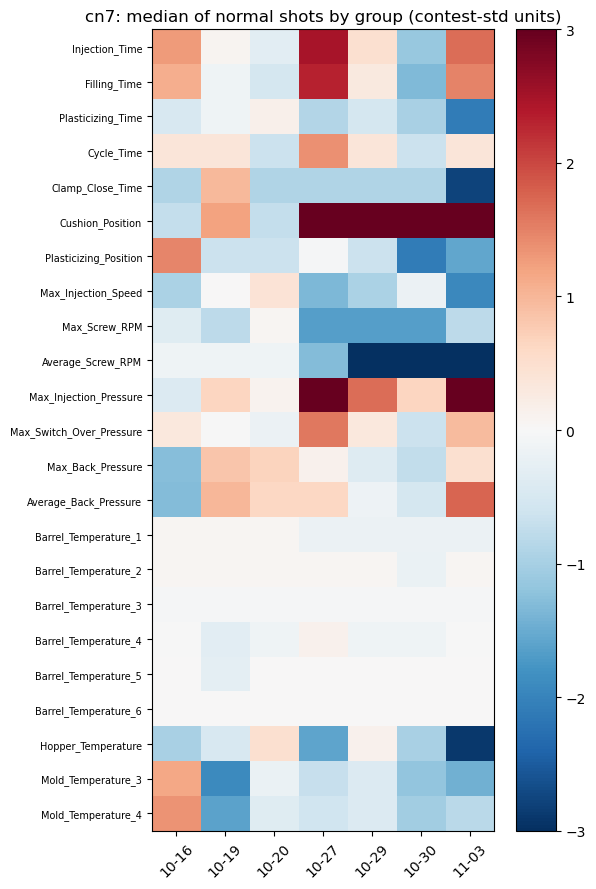


===== rg3: 그룹별 정상 사출 중앙값 (대회 형식 단위) =====
                            B1    B2    B3    B4    B5    11-04    11-05    11-06
Injection_Time           -0.03 -0.03 -0.03 -0.03 -0.03     8.57     8.57     8.57
Filling_Time             -1.19 -1.19 -1.19  0.84  0.84     2.87     0.84     0.84
Plasticizing_Time         1.98  0.63 -0.04 -0.27 -0.83     4.67     0.86     0.41
Cycle_Time                0.25  0.25  0.25  0.25  0.25     0.25     0.25    -1.40
Clamp_Close_Time          1.03 -0.39  1.03 -0.39 -1.81    -1.81    -1.81    -1.81
Cushion_Position          1.28  0.48  0.48 -1.11 -1.11    -1.11     1.28     0.48
Plasticizing_Position     0.59  0.59 -0.97  0.59  0.59     2.15     6.84     6.06
Max_Injection_Speed       1.40  0.62  0.62 -0.95 -0.95    -8.02    -1.74    -2.52
Max_Screw_RPM             0.68  0.01 -0.67 -0.67  0.01     2.02     0.68    -0.67
Average_Screw_RPM         1.12 -0.42 -0.42 -0.42 -0.42 -4024.09 -4024.09 -4024.09
Max_Injection_Pressure   -1.42 -0.11 -0.11  0.55  0.55 

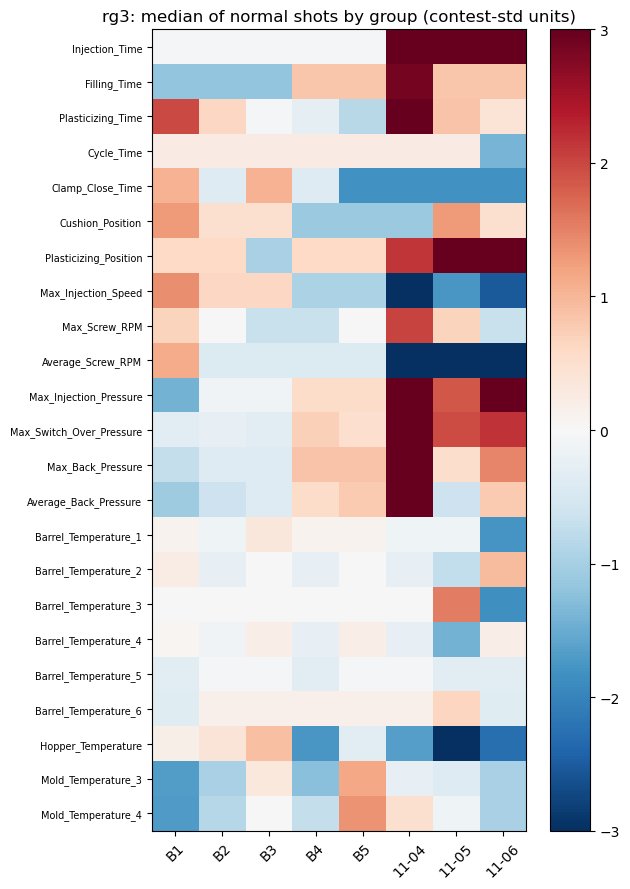

In [30]:
import matplotlib.pyplot as plt

def group_label(g, mold):
    """rg3 대회 범위는 묶음, 나머지는 날짜"""
    lab = g['t'].dt.strftime('%m-%d')
    if mold == 'rg3':
        lab = np.where(g['period'] == 'contest', 'B' + g['bundle'].astype(str), lab)
    return pd.Series(lab, index=g.index)

SHIFT = {}
for mold in MOLDS:
    d = D[mold]; g = d['g']
    X = to_contest_units(g, d['sc'])                          # 대회 형식 단위 (1 = 대회 범위 표준편차 1개)
    lab = group_label(g, mold)
    normal = g['y'] == 0                                      # 정상 사출만 (불량 영향 제외)
    med = X[normal].groupby(lab[normal]).median()
    order = sorted(med.index, key=lambda s: (not s.startswith('B'), s))
    med = med.loc[order]
    SHIFT[mold] = med
    print(f'\n===== {mold}: 그룹별 정상 사출 중앙값 (대회 형식 단위) =====')
    print(med.round(2).T.to_string())
    print('\n그룹 간 중앙값 차이(최대-최소)가 큰 변수 상위 8개:')
    print((med.max() - med.min()).sort_values(ascending=False).head(8).round(2).to_string())
    med.to_csv(f'{FA}7_2_shift_{mold}.csv', encoding='utf-8-sig')

    fig, ax = plt.subplots(figsize=(max(6, len(med) * 0.8), 9))
    im = ax.imshow(med.T.values, aspect='auto', cmap='RdBu_r', vmin=-3, vmax=3)
    ax.set_xticks(range(len(med))); ax.set_xticklabels(med.index, rotation=45)
    ax.set_yticks(range(med.shape[1])); ax.set_yticklabels(med.columns, fontsize=7)
    ax.set_title(f'{mold}: median of normal shots by group (contest-std units)')
    fig.colorbar(im, ax=ax); fig.tight_layout()
    fig.savefig(f'{FA}7_2_shift_{mold}.png', dpi=120); plt.show(); plt.close(fig)

### 7-3. 불량이 직전 사출보다 튀었나 (2차 진행 여부 판단)

- 각 사출의 값에서 같은 연속 구간 직전 10사출의 중앙값을 뺀 변화량을 불량과 양품에서 비교. 미래 정보는 쓰지 않음.
- AUC 0.5 = 차이 없음, 1.0 = 불량이 항상 더 튐. 0.70 이상인 변수가 있으면 2차 진행 (실행 전 확정).

In [31]:
from sklearn.metrics import roc_auc_score
N_PREV = 10                                                   # 직전 N사출 (실행 전 고정)

def delta_prev(g, sc, n=N_PREV):
    """각 사출의 값 - 같은 연속 구간 안 직전 n사출의 중앙값 (미래 정보 사용 안 함)"""
    X = to_contest_units(g, sc)
    base = X.groupby(g['seg']).transform(lambda s: s.shift(1).rolling(n, min_periods=5).median())
    return X - base

JUMP = {}
for mold in MOLDS:
    d = D[mold]; g = d['g']
    c = (g['period'] == 'contest').values
    dlt = delta_prev(g, d['sc'])[c].abs()
    y = g['y'].values[c]
    ok = dlt.notna().all(axis=1).values                      # 직전 사출이 5개 미만인 앞부분 제외
    rows = []
    for v in dlt.columns:
        a, yy = dlt[v].values[ok], y[ok]
        rows.append(dict(변수=v, 불량_변화량중앙=np.median(a[yy == 1]), 양품_변화량중앙=np.median(a[yy == 0]),
                         AUC=roc_auc_score(yy, a) if 0 < yy.sum() < len(yy) else np.nan))
    allv = dlt.max(axis=1).values[ok]
    rows.append(dict(변수='(전 변수 중 최대)', 불량_변화량중앙=np.median(allv[y[ok] == 1]),
                     양품_변화량중앙=np.median(allv[y[ok] == 0]), AUC=roc_auc_score(y[ok], allv)))
    T = pd.DataFrame(rows).sort_values('AUC', ascending=False)
    JUMP[mold] = T
    print(f'\n===== {mold}: 직전 {N_PREV}사출 대비 변화량 (불량 {int(y[ok].sum())}개 / 양품 {int((y[ok] == 0).sum())}개) =====')
    print(T.round(3).to_string(index=False))
    T.to_csv(f'{FA}7_3_jump_{mold}.csv', index=False, encoding='utf-8-sig')


===== cn7: 직전 10사출 대비 변화량 (불량 14개 / 양품 582개) =====
                      변수  불량_변화량중앙  양품_변화량중앙   AUC
             (전 변수 중 최대)     1.904     1.822 0.646
    Barrel_Temperature_6     1.366     0.683 0.635
  Max_Injection_Pressure     0.784     0.523 0.634
     Max_Injection_Speed     0.535     0.195 0.628
           Max_Screw_RPM     1.268     0.845 0.624
          Injection_Time     0.401     0.401 0.617
    Barrel_Temperature_5     0.923     0.615 0.605
            Filling_Time     0.504     0.403 0.595
      Hopper_Temperature     0.252     0.151 0.594
        Cushion_Position     0.000     0.000 0.587
       Max_Back_Pressure     0.352     0.264 0.579
   Average_Back_Pressure     0.381     0.381 0.572
      Mold_Temperature_3     0.072     0.036 0.564
Max_Switch_Over_Pressure     0.871     0.633 0.556
        Clamp_Close_Time     0.000     0.000 0.553
    Barrel_Temperature_1     0.617     0.673 0.539
              Cycle_Time     0.000     0.000 0.535
    Barrel_Temperature_3     0

### 7-4. 미래 기간 극단 점수·전체 경보의 원인 변수

- (1) cn7 미래 불량 사출의 극단 점수: 최종 로지스틱의 변수별 기여도(계수 × 표준화 입력값)와 대회 범위 대비 위치
- (2) rg3 11/04 전체 경보: 이상점수 학습 데이터(과거 비라벨) 대비 변수별 이동

In [32]:
# (1) cn7: 최종 로지스틱 모델의 변수별 기여도 = 계수 × 표준화된 입력값
if 'MODELS' not in globals():                                # 6-1을 이번 세션에 안 돌렸으면 저장 파일에서 불러옴
    MODELS = {m: joblib.load(f'./output/final/final_{m}.joblib') for m in MOLDS}
d = D['cn7']; M = MODELS['cn7']
Fc = d['g'][d['g']['period'] == 'future'].reset_index(drop=True)
Cc = d['g'][d['g']['period'] == 'contest'].reset_index(drop=True)
Xf = M['model'].cols(make_X(Fc, d['sc'], d['ifm'], hybrid=True))
Xc = M['model'].cols(make_X(Cc, d['sc'], d['ifm'], hybrid=True))
pipe = M['model'].m
if hasattr(pipe, 'named_steps') and 'logisticregression' in pipe.named_steps:
    scl, lr = pipe.named_steps['standardscaler'], pipe.named_steps['logisticregression']
    i_bad = int(np.where(Fc['y'].values == 1)[0][0])
    z = scl.transform(Xf.iloc[[i_bad]])[0]
    contrib = pd.DataFrame(dict(변수=Xf.columns, 입력값_대회단위=Xf.iloc[i_bad].values,
                                학습범위_최소=Xc.min().values, 학습범위_최대=Xc.max().values,
                                계수=lr.coef_[0], 기여도=lr.coef_[0] * z))
    contrib = contrib.reindex(contrib['기여도'].abs().sort_values(ascending=False).index)
    print(f"cn7 미래 불량 사출 ({Fc.loc[i_bad, 't']}) 점수 = {lr.intercept_[0] + contrib['기여도'].sum():.1f}")
    print(contrib.head(10).round(3).to_string(index=False))
    contrib.to_csv(f'{FA}7_4_cn7_contrib.csv', index=False, encoding='utf-8-sig')
else:
    print('cn7 최종 모델이 로지스틱이 아니라 이 분석은 해당 없음:', M['cand_name'])

# 미래 기간에 학습 범위를 벗어난 비율 (변수별)
out_rate = ((Xf < Xc.min()) | (Xf > Xc.max())).mean().sort_values(ascending=False)
print('\ncn7 미래 사출 중 대회 범위 최소~최대를 벗어난 비율 (상위 8개):')
print(out_rate.head(8).round(3).to_string())

# (2) rg3: 11/04 사출이 이상점수 학습 데이터(과거 비라벨) 범위를 얼마나 벗어났나
d = D['rg3']
_, unl_shots = build_unlabeled_past('rg3')
Xu = to_contest_units(unl_shots, d['sc'])
Fr = d['g'][d['g']['period'] == 'future'].reset_index(drop=True)
Xr = to_contest_units(Fr, d['sc'])
day = Fr['t'].dt.strftime('%m-%d') == '11-04'
rg3_shift = pd.DataFrame(dict(
    벗어난비율=((Xr[day] < Xu.min()) | (Xr[day] > Xu.max())).mean(),
    중앙값이동_학습표준편차단위=(Xr[day].median() - Xu.median()) / Xu.std().replace(0, np.nan)))
rg3_shift = rg3_shift.reindex(rg3_shift['중앙값이동_학습표준편차단위'].abs().sort_values(ascending=False).index)
print(f'\nrg3 11/04 ({int(day.sum())}사출): 이상점수 학습 데이터(과거 비라벨 {len(Xu)}사출) 대비')
print(rg3_shift.head(10).round(3).to_string())
rg3_shift.to_csv(f'{FA}7_4_rg3_1104_shift.csv', encoding='utf-8-sig')

cn7 미래 불량 사출 (2020-11-03 04:44:17) 점수 = -3038.9
                   변수  입력값_대회단위  학습범위_최소  학습범위_최대     계수       기여도
    Average_Screw_RPM -3050.457   -1.291   16.087  0.989 -3017.316
     Clamp_Close_Time    -2.783   -0.902    2.860  2.331    -6.491
   Hopper_Temperature    -2.788   -2.083    2.550  2.068    -5.757
  Max_Injection_Speed    -1.931   -1.542    9.556  1.758    -3.393
         Filling_Time     1.894   -7.777    2.297  1.406     2.661
Plasticizing_Position    -1.427   -2.877    1.592  1.725    -2.464
       Injection_Time     2.080   -7.549    2.080  1.079     2.242
   Mold_Temperature_3    -0.837   -1.910    1.381  2.102    -1.761
 Barrel_Temperature_1     2.524   -2.636    3.197 -0.671    -1.692
 Barrel_Temperature_4     1.397   -2.047    2.545  0.856     1.197

cn7 미래 사출 중 대회 범위 최소~최대를 벗어난 비율 (상위 8개):
Average_Screw_RPM         0.785
Plasticizing_Time         0.770
Max_Injection_Pressure    0.565
Hopper_Temperature        0.373
Max_Injection_Speed       0.318
Clamp_Close_T

### 7-5. 불량 종류별 조건 차이

- 불량 사출의 값이 같은 연속 구간 정상 사출 중앙값보다 얼마나 다른지를 불량 종류(가스/미성형)별로 비교. 개수가 적은 종류는 참고만.

In [33]:
rows = []
for mold in MOLDS:
    d = D[mold]; g = d['g']
    X = to_contest_units(g, d['sc'])
    key = g['seg']                                              # 같은 연속 구간의 정상 사출 중앙값과 비교
    base = X[g['y'] == 0].groupby(key[g['y'] == 0]).median()
    rel = X - base.reindex(key).values
    for (per, rs), idx in g[g['y'] == 1].groupby(['period', 'reason']).groups.items():
        r = rel.loc[idx].median()
        rows.append(dict(금형=mold, 기간=per, 불량종류=rs, 개수=len(idx), **r.round(2).to_dict()))
KIND = pd.DataFrame(rows)
print('불량 종류별: 같은 구간 정상 사출 중앙값 대비 차이 (대회 형식 단위, 중앙값)')
show = KIND.set_index(['금형', '기간', '불량종류', '개수']).T
print(show.reindex(show.abs().max(axis=1).sort_values(ascending=False).index).head(12).to_string())
KIND.to_csv(f'{FA}7_5_defect_kind.csv', index=False, encoding='utf-8-sig')

불량 종류별: 같은 구간 정상 사출 중앙값 대비 차이 (대회 형식 단위, 중앙값)
금형                           cn7                          rg3                   
기간                       contest               future contest       future      
불량종류                          가스 가스/미성형    미성형    미성형      가스   미성형     가스   미성형
개수                            11     2      1      1       17    8      5     2 
Max_Injection_Speed         0.00  10.42  10.12   0.00    0.00  0.00   0.00 -0.39
Injection_Time              0.00  -5.42  -5.22   0.40    0.00  0.00   0.00  8.60
Filling_Time                0.00  -5.24  -5.24   0.40    0.00  0.00   0.00  0.00
Max_Injection_Pressure      1.05  -3.14  -3.14   0.00    0.00  0.16   0.66  1.31
Max_Screw_RPM              -0.42   0.42   0.42  -0.85    0.67  0.34  -2.69 -1.34
Barrel_Temperature_1       -0.22   0.34  -2.02   2.69    0.00 -0.12  -0.23 -0.47
Cycle_Time                  0.00  -2.29   1.53   0.00    0.00  0.00   0.00  0.00
Cushion_Position            0.00  -1.90  -1.90   0.00    0.00  

### 7-6. 추가 확인

(1) Average_Screw_RPM 원래 값이 날짜별로 어떻게 바뀌었는지
(2) cn7 양쪽 불량 사출과 미성형 관련 사출이 같은 사출인지
(3) 회전수 기록 변화가 실제 공정 변화인지: 날짜별 평균·최대 회전수와 가소화 시간 비교

In [34]:
# (1) Average_Screw_RPM 원래 값 (단위 변환 전) 날짜별 분포
for mold in MOLDS:
    g = D[mold]['g']
    s = g.groupby(g['t'].dt.strftime('%m-%d'))['Average_Screw_RPM'].describe()[['count', 'min', '50%', 'max']]
    print(f'\n===== {mold}: Average_Screw_RPM 원래 값 =====')
    print(s.round(2).to_string())
    print('대회 범위 평균·표준편차(단위 변환 기준):',
          round(D[mold]['sc']['mean']['Average_Screw_RPM'], 3), round(D[mold]['sc']['std']['Average_Screw_RPM'], 4))

# (2) cn7 대회 범위 불량 사출: 좌우 불량 개수와 불량 종류
d = _read(f'{RAW}labeled_full_cn7_raw.csv').drop_duplicates('_id')
d['t'] = pd.to_datetime(d['TimeStamp'])
d['bad'] = (d['PassOrFail'].astype(str).str.upper() == 'N').astype(int)
g = D['cn7']['g']
bad_shots = g[(g['period'] == 'contest') & (g['y'] == 1)][['t', 'reason', 'Max_Injection_Speed', 'Injection_Time']]
nb = d.groupby('t')['bad'].sum().rename('불량줄수')
print('\ncn7 대회 범위 불량 사출:')
print(bad_shots.merge(nb, left_on='t', right_index=True).to_string(index=False))


# (3) 날짜별 평균 회전수 vs 최대 회전수, 가소화 시간 (원래 값, 정상 사출 중앙값)
for mold in MOLDS:
    g = D[mold]['g']
    n = g[g['y'] == 0]
    t = n.groupby(n['t'].dt.strftime('%m-%d'))[['Average_Screw_RPM', 'Max_Screw_RPM', 'Plasticizing_Time']].median()
    t['평균>최대'] = t['Average_Screw_RPM'] > t['Max_Screw_RPM']
    print(f'\n===== {mold}: 날짜별 정상 사출 중앙값 (원래 값) =====')
    print(t.round(2).to_string())
    t.to_csv(f'{FA}7_6_rpm_check_{mold}.csv', encoding='utf-8-sig')


===== cn7: Average_Screw_RPM 원래 값 =====
       count    min    50%    max
t                                
10-16  188.0  292.4  292.5  292.5
10-19   36.0  292.4  292.5  292.5
10-20  382.0  292.4  292.5  293.9
10-27  309.0  292.3  292.4  292.5
10-29  230.0   29.2   29.2   29.4
10-30  382.0   29.2   29.2   29.4
11-03  463.0   29.2   29.2   29.2
대회 범위 평균·표준편차(단위 변환 기준): 292.511 0.0863

===== rg3: Average_Screw_RPM 원래 값 =====
       count    min    50%    max
t                                
10-21   41.0  290.5  290.6  290.7
10-22  300.0  290.4  290.5  290.7
10-23  250.0  290.4  290.5  290.7
11-04   36.0   29.0   29.0   29.0
11-05    1.0   29.0   29.0   29.0
11-06    1.0   29.0   29.0   29.0
대회 범위 평균·표준편차(단위 변환 기준): 290.527 0.065

cn7 대회 범위 불량 사출:
                  t reason  Max_Injection_Speed  Injection_Time  불량줄수
2020-10-16 05:21:38     가스            55.400002            9.58     1
2020-10-16 05:37:29     가스            55.299999            9.60     1
2020-10-16 05:45:26     가스       

# 8. 보조 분석

### 8-1. 비지도 단독 단순성 순위 민감도
비지도 단독(IF_only)을 단순성 순서의 다른 위치에 두었을 때 rg3 최종 후보가 바뀌는지 확인. (모델 재학습 없음, 선정 규칙만 다시 적용)

In [35]:
# 비지도 단독(IF_only)의 단순성 위치에 따라 rg3 최종 후보가 바뀌는지 확인
mean_pr = RG3_MOCK.groupby('cand')['pr_auc'].mean()       # SVM=XGB 동률일 때만 사용
wins_u = pd.Series(RG3_WIN).unique()
print('라운드별 1등:', RG3_WIN)

rows = []
for label, if_rank in [('가장 단순 (현재 규칙)', -1), ('로지스틱과 같음', 0),
                       ('랜덤포레스트와 같음', 1), ('SVM·XGB와 같음', 2), ('가장 복잡', 3)]:
    W = pd.DataFrame(dict(cand=wins_u))
    W['s0'] = W['cand'].map(lambda x: if_rank if x == 'IF_only' else simple_of(x)[0])
    W['s1'] = W['cand'].map(lambda x: 0 if x == 'IF_only' else simple_of(x)[1])
    W['mean_pr'] = W['cand'].map(mean_pr)
    pick = W.sort_values(['s0', 's1', 'mean_pr'], ascending=[True, True, False]).iloc[0]['cand']
    rows.append(dict(비지도_순위=label, rg3_최종후보=pick))

SENS = pd.DataFrame(rows)
print(SENS.to_string(index=False))
SENS.to_csv(f'{FA}8_1_if_rank_sensitivity.csv', index=False, encoding='utf-8-sig')

라운드별 1등: {1: 'XGB_base', 2: 'SVM_hyb', 3: 'IF_only', 4: 'IF_only', 5: 'IF_only'}
       비지도_순위 rg3_최종후보
가장 단순 (현재 규칙)  IF_only
     로지스틱과 같음  IF_only
   랜덤포레스트와 같음  IF_only
  SVM·XGB와 같음  IF_only
        가장 복잡 XGB_base


# 9. 현장 운영안

### 9-1. 검사 우선순위

같은 날짜·묶음 안에서 점수가 높은 순으로 상위 X%만 검사할 때 불량을 몇 % 잡는지 확인.
배율 = 불량 포착률 ÷ 검사 비율 (1이면 무작위로 골라 검사한 것과 같음)
- rg3 시험지: 라운드 1등 모델의 시험지 예측
- 이상점수: 라벨을 쓰지 않은 모델이라 대회 범위 전체를 학습에 안 쓴 데이터로 평가 가능

In [36]:
OPS = './output/operation/'
os.makedirs(OPS, exist_ok=True)
TOP = [0.05, 0.10, 0.20, 0.30, 0.50]                          # 검사 비율 (점수 상위 X%)

def priority_table(y, score, group, name):
    """그룹(날짜·묶음) 안에서 점수 순위를 매겨 상위 X%만 검사할 때 잡히는 불량 비율.
    배율 = 잡은 불량 비율 ÷ 검사 비율 (1이면 무작위 검사와 같음)"""
    df = pd.DataFrame(dict(y=np.asarray(y), s=np.asarray(score), g=np.asarray(group)))
    df['pct'] = df.groupby('g')['s'].rank(ascending=False, pct=True, method='first')
    rows = []
    for x in TOP:
        hit = df['pct'] <= x
        cap = df.loc[hit, 'y'].sum() / df['y'].sum()
        rows.append(dict(대상=name, 검사비율=x, 검사사출=int(hit.sum()), 잡은불량=int(df.loc[hit, 'y'].sum()),
                         전체불량=int(df['y'].sum()), 불량포착률=round(cap, 3), 배율=round(cap / x, 2)))
    return pd.DataFrame(rows)

tbls = []
# (1) rg3 시험지 5개 (라운드 1등 모델 예측, 묶음 안에서 순위)
P = pd.read_csv(f'{RES}rg3_test_pred.csv')
tbls.append(priority_table(P['y'], P['score'], P['test_bundle'], 'rg3 시험지 (라운드 1등)'))
# (2) 이상점수 (라벨을 안 쓰므로 대회 범위 전체가 학습에 쓰이지 않은 데이터, 구간 안에서 순위)
for mold in MOLDS:
    g = D[mold]['g']; c = g[g['period'] == 'contest']
    tbls.append(priority_table(c['y'], c['anomaly_score'], c['seg'], f'{mold} 대회 범위 (이상점수)'))
PRIO = pd.concat(tbls, ignore_index=True)
print(PRIO.to_string(index=False))
PRIO.to_csv(f'{OPS}9_1_inspection_priority.csv', index=False, encoding='utf-8-sig')

              대상  검사비율  검사사출  잡은불량  전체불량  불량포착률   배율
rg3 시험지 (라운드 1등)  0.05    27     0    25  0.000 0.00
rg3 시험지 (라운드 1등)  0.10    57     0    25  0.000 0.00
rg3 시험지 (라운드 1등)  0.20   116     1    25  0.040 0.20
rg3 시험지 (라운드 1등)  0.30   175     5    25  0.200 0.67
rg3 시험지 (라운드 1등)  0.50   294     9    25  0.360 0.72
cn7 대회 범위 (이상점수)  0.05    29     1    14  0.071 1.43
cn7 대회 범위 (이상점수)  0.10    59     2    14  0.143 1.43
cn7 대회 범위 (이상점수)  0.20   120     5    14  0.357 1.79
cn7 대회 범위 (이상점수)  0.30   181     8    14  0.571 1.90
cn7 대회 범위 (이상점수)  0.50   303     9    14  0.643 1.29
rg3 대회 범위 (이상점수)  0.05    26     0    25  0.000 0.00
rg3 대회 범위 (이상점수)  0.10    55     1    25  0.040 0.40
rg3 대회 범위 (이상점수)  0.20   115     2    25  0.080 0.40
rg3 대회 범위 (이상점수)  0.30   174     7    25  0.280 0.93
rg3 대회 범위 (이상점수)  0.50   294    10    25  0.400 0.80


### 9-2. 3단계 판정 (불량 / 재검사 / 통과)
정상 사출 상위 0.5% 기준선 이상 = 불량, 0.5%~2% 사이 = 재검사, 나머지 = 통과 (실행 전 확정 ③)

In [37]:
def three_from_alarms(df):
    return np.where(df['alarm_0.005'], '불량', np.where(df['alarm_0.02'], '재검사', '통과'))

rows = []
P = pd.read_csv(f'{RES}rg3_test_pred.csv')
P['판정'] = three_from_alarms(P)
for (yy, j), n in P.groupby(['y', '판정']).size().items():
    rows.append(dict(대상='rg3 시험지 (라운드 1등)', 실제='불량' if yy == 1 else '정상', 판정=j, 사출수=n))
for mold in MOLDS:
    F = pd.read_csv(f'{FIN}future_{mold}_pred.csv')
    for (yy, j), n in F.groupby(['y', '판정_3단계']).size().items():
        rows.append(dict(대상=f'{mold} 미래 기간 (최종 모델)', 실제='불량' if yy == 1 else '정상', 판정=j, 사출수=n))
THREE = pd.DataFrame(rows).pivot_table(index=['대상', '실제'], columns='판정', values='사출수',
                                       aggfunc='sum', fill_value=0)
THREE = THREE.reindex(columns=[c for c in ['불량', '재검사', '통과'] if c in THREE.columns])
print(THREE.to_string())
THREE.to_csv(f'{OPS}9_2_three_way.csv', encoding='utf-8-sig')

판정                    불량  재검사    통과
대상                실제               
cn7 미래 기간 (최종 모델) 불량   0    0     1
                  정상   0    0  1383
rg3 미래 기간 (최종 모델) 불량   7    0     0
                  정상  29    0     2
rg3 시험지 (라운드 1등)  불량   3    0    22
                  정상  70   23   473


### 9-3. 입력 범위 검사 효과
판정 전에 입력값이 학습 범위(대회 범위 최소~최대를 양쪽으로 10%씩 넓힌 범위)를 벗어나면 "판정 보류,
센서·설정 확인"으로 처리했다면 미래 기간에서 몇 %가 보류됐을지 확인. (10%는 운영 예시 조건)

In [38]:
MARGIN = 0.10      # 허용 범위 = 대회 범위 최소~최대를 양쪽으로 (최대-최소)의 10%씩 넓힌 것 (운영 예시 조건)

def range_check(train, new, feats, margin=MARGIN):
    """학습 범위를 벗어난 변수가 하나라도 있으면 판정 보류. 반환: (보류 여부, 벗어난 변수 목록)"""
    lo, hi = train[feats].min(), train[feats].max()
    w = (hi - lo) * margin
    out = (new[feats] < lo - w) | (new[feats] > hi + w)
    return out.any(axis=1), out

rows, var_rows = [], []
for mold in MOLDS:
    g, feats = D[mold]['g'], D[mold]['sc']['feats']
    c = g[g['period'] == 'contest']; f = g[g['period'] == 'future']
    hold, out = range_check(c, f, feats)
    day = f['t'].dt.strftime('%m-%d')
    for dname, idx in f.groupby(day).groups.items():
        rows.append(dict(금형=mold, 날짜=dname, 사출=len(idx), 판정보류=int(hold.loc[idx].sum()),
                         보류비율=round(hold.loc[idx].mean(), 3),
                         불량=int(f.loc[idx, 'y'].sum()), 보류된불량=int((hold.loc[idx] & (f.loc[idx, 'y'] == 1)).sum())))
    var_rows.append(out.mean().rename(mold))
HOLD = pd.DataFrame(rows)
print(HOLD.to_string(index=False))
VAR = pd.concat(var_rows, axis=1)
VAR = VAR.loc[VAR.max(axis=1).sort_values(ascending=False).index]
print('\n변수별 범위 이탈 비율 (미래 기간, 상위 8개):')
print(VAR.head(8).round(3).to_string())
HOLD.to_csv(f'{OPS}9_3_range_check.csv', index=False, encoding='utf-8-sig')
VAR.to_csv(f'{OPS}9_3_range_check_by_var.csv', index=False, encoding='utf-8-sig')

 금형    날짜  사출  판정보류  보류비율  불량  보류된불량
cn7 10-27 309   243 0.786   0      0
cn7 10-29 230   230 1.000   0      0
cn7 10-30 382   382 1.000   0      0
cn7 11-03 463   463 1.000   1      1
rg3 11-04  36    36 1.000   7      7
rg3 11-05   1     1 1.000   0      0
rg3 11-06   1     1 1.000   0      0

변수별 범위 이탈 비율 (미래 기간, 상위 8개):
                            cn7    rg3
Average_Screw_RPM         0.777  1.000
Max_Injection_Speed       0.015  0.947
Max_Back_Pressure         0.013  0.947
Max_Switch_Over_Pressure  0.012  0.947
Max_Injection_Pressure    0.483  0.842
Average_Back_Pressure     0.014  0.763
Filling_Time              0.027  0.737
Plasticizing_Time         0.000  0.684


# 10. 보고서용 평가 설계 근거

### 10-1. 끊김 기준별 구간 수
연속 기록 구간을 나누는 끊김 기준(5분~2시간)을 바꿔도 구간 수가 같은지 확인. 묶는 기준이 결과를 좌우하지 않는다는 근거.

In [39]:
REP = './output/report/'
os.makedirs(REP, exist_ok=True)

rows = []
for mold in MOLDS:
    c = D[mold]['g']; c = c[c['period'] == 'contest'].sort_values('t')
    for m in [5, 10, 20, 30, 60, 90, 120]:
        seg = (c['t'].diff() > pd.Timedelta(f'{m}min')).cumsum()
        bad = c.groupby(seg)['y'].sum()
        rows.append(dict(금형=mold, 끊김기준_분=m, 구간수=seg.nunique(),
                         불량있는구간=int((bad > 0).sum()), 구간별불량=list(bad.values)))
GAP = pd.DataFrame(rows)
print(GAP.to_string(index=False))
GAP.to_csv(f'{REP}10_1_gap_segments.csv', index=False, encoding='utf-8-sig')

 금형  끊김기준_분  구간수  불량있는구간                  구간별불량
cn7       5    2       1                [14, 0]
cn7      10    2       1                [14, 0]
cn7      20    2       1                [14, 0]
cn7      30    2       1                [14, 0]
cn7      60    2       1                [14, 0]
cn7      90    2       1                [14, 0]
cn7     120    2       1                [14, 0]
rg3       5    7       6 [0, 4, 1, 10, 2, 2, 6]
rg3      10    7       6 [0, 4, 1, 10, 2, 2, 6]
rg3      20    5       4       [0, 5, 10, 4, 6]
rg3      30    5       4       [0, 5, 10, 4, 6]
rg3      60    5       4       [0, 5, 10, 4, 6]
rg3      90    5       4       [0, 5, 10, 4, 6]
rg3     120    5       4       [0, 5, 10, 4, 6]


### 10-2. 시간 차이별 센서 값 차이
대회 범위의 모든 사출 쌍에 대해, 두 사출의 시간 차이별로 센서 값 차이(변수별 차이 평균, 대회 형식 단위)의 중앙값을 비교.
시간이 가까운 사출일수록 값이 비슷하다면, 랜덤 분할 시 거의 같은 사출이 학습과 시험에 나뉘어 들어가 점수가 부풀려.

 금형   시간차이   쌍개수  센서차이_중앙값
cn7    ~2분   994     0.532
cn7  2~10분  4921     0.608
cn7 10~30분 11255     0.607
cn7 30~60분 15391     0.636
cn7  1~2시간 25601     0.687
cn7  2~6시간 44973     0.884
cn7 6~24시간  1596     1.116
cn7  하루 이상 78584     1.268
rg3    ~2분   570     0.609
rg3  2~10분  4326     0.736
rg3 10~30분  9174     0.728
rg3 30~60분 10528     0.747
rg3  1~2시간 13389     0.769
rg3  2~6시간 33189     0.916
rg3 6~24시간 41520     1.083
rg3  하루 이상 61649     1.160


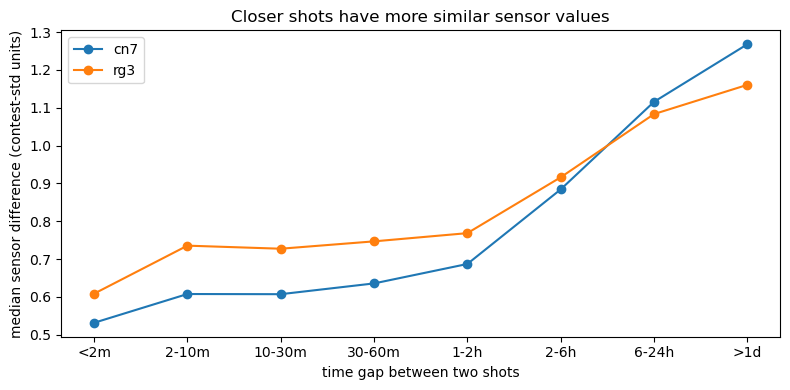

In [40]:
import matplotlib.pyplot as plt
BINS = [(0, 2, '~2분'), (2, 10, '2~10분'), (10, 30, '10~30분'), (30, 60, '30~60분'),
        (60, 120, '1~2시간'), (120, 360, '2~6시간'), (360, 1440, '6~24시간'), (1440, 1e9, '하루 이상')]

rows = []
for mold in MOLDS:
    d = D[mold]; c = d['g'][d['g']['period'] == 'contest'].reset_index(drop=True)
    X = to_contest_units(c, d['sc']).values
    tm = (c['t'] - c['t'].min()).dt.total_seconds().values / 60
    i, j = np.triu_indices(len(c), k=1)                       # 모든 사출 쌍
    gap = np.abs(tm[j] - tm[i])
    diff = np.abs(X[j] - X[i]).mean(axis=1)                    # 쌍의 변수별 차이 평균 (대회 형식 단위)
    for lo, hi, lab in BINS:
        k = (gap >= lo) & (gap < hi)
        if k.sum():
            rows.append(dict(금형=mold, 시간차이=lab, 쌍개수=int(k.sum()), 센서차이_중앙값=float(np.median(diff[k]))))
SIM = pd.DataFrame(rows)
print(SIM.round(3).to_string(index=False))
SIM.to_csv(f'{REP}10_2_time_gap_diff.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(8, 4))
order = [b[2] for b in BINS]
for mold in MOLDS:
    s = SIM[SIM['금형'] == mold].set_index('시간차이').reindex(order)['센서차이_중앙값']
    ax.plot(range(len(order)), s.values, 'o-', label=mold)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(['<2m', '2-10m', '10-30m', '30-60m', '1-2h', '2-6h', '6-24h', '>1d'])
ax.set_xlabel('time gap between two shots'); ax.set_ylabel('median sensor difference (contest-std units)')
ax.set_title('Closer shots have more similar sensor values'); ax.legend(); fig.tight_layout()
fig.savefig(f'{REP}10_2_time_gap_diff.png', dpi=120); plt.show(); plt.close(fig)

### 10-3. 랜덤 분할 vs 시간 분할 (평가 함정)
같은 모델(로지스틱, 랜덤포레스트 기본)로 나누는 방식만 바꿔 PR-AUC를 비교한다. 모델 선택에는 쓰지 않는 설명용 실험.
- 랜덤 (줄 단위): 대회 파일처럼 좌우를 별도 행으로 두고 무작위로 나눔 → 같은 사출의 좌우가 학습·시험에 갈라짐
- 랜덤 (사출 단위): 사출을 무작위로 나눔 → 바로 옆 사출이 학습·시험에 갈라짐
- 시간 (30분 블록 단위): 30분 블록을 통째로 나눔

 금형 모델               나누는방식  PR_AUC
cn7 LR 랜덤 (줄 단위, 대회 파일 형식)   0.459
cn7 LR          랜덤 (사출 단위)   0.361
cn7 LR      시간 (30분 블록 단위)   0.073
cn7 RF 랜덤 (줄 단위, 대회 파일 형식)   0.439
cn7 RF          랜덤 (사출 단위)   0.289
cn7 RF      시간 (30분 블록 단위)   0.038
cn7  -       찍기 수준 (불량 비율)   0.023
rg3 LR 랜덤 (줄 단위, 대회 파일 형식)   0.020
rg3 LR          랜덤 (사출 단위)   0.036
rg3 LR      시간 (30분 블록 단위)   0.038
rg3 RF 랜덤 (줄 단위, 대회 파일 형식)   0.030
rg3 RF          랜덤 (사출 단위)   0.044
rg3 RF      시간 (30분 블록 단위)   0.041
rg3  -       찍기 수준 (불량 비율)   0.042


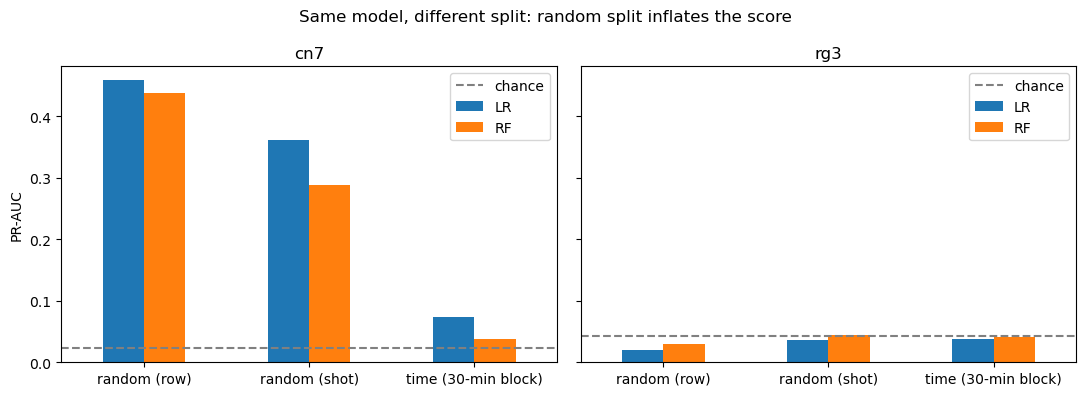

In [41]:
from sklearn.model_selection import StratifiedKFold, GroupKFold

def oof_pr_auc(key, X, y, splits):
    """나눈 방식(splits)대로 학습·예측해서 합친 예측으로 PR-AUC 1번 계산"""
    s = np.zeros(len(y))
    for tr, te in splits:
        if y[tr].sum() == 0:                                   # 학습 쪽 불량 0개면 정보 없음
            s[te] = 0.0
            continue
        m = Candidate(key).fit(X.iloc[tr], y[tr])
        s[te] = m.score(X.iloc[te])
    return pr_auc(y, s)

rows = []
for mold in MOLDS:
    d = D[mold]
    # (a) 대회 파일 형식: 좌우를 별도 행으로 둔 줄 단위
    r = _read(f'{RAW}labeled_full_{mold}_raw.csv').drop_duplicates('_id')
    r['t'] = pd.to_datetime(r['TimeStamp'])
    r = r[r['t'].isin(d['g'].loc[d['g']['period'] == 'contest', 't'])].reset_index(drop=True)
    Xr = to_contest_units(r, d['sc']); yr = (r['PassOrFail'].astype(str).str.upper() == 'N').astype(int).values
    # (b) 사출 단위
    c = d['g'][d['g']['period'] == 'contest'].reset_index(drop=True)
    Xs = to_contest_units(c, d['sc']); ys = c['y'].values
    blk = ((c['t'] - c['t'].min()) // pd.Timedelta('30min')).values   # 30분 블록
    for key in ['LR', 'RF']:
        rnd_row = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xr, yr))
        rnd_shot = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xs, ys))
        time_blk = list(GroupKFold(5).split(Xs, ys, blk))
        rows += [dict(금형=mold, 모델=key, 나누는방식='랜덤 (줄 단위, 대회 파일 형식)', PR_AUC=oof_pr_auc(key, Xr, yr, rnd_row)),
                 dict(금형=mold, 모델=key, 나누는방식='랜덤 (사출 단위)', PR_AUC=oof_pr_auc(key, Xs, ys, rnd_shot)),
                 dict(금형=mold, 모델=key, 나누는방식='시간 (30분 블록 단위)', PR_AUC=oof_pr_auc(key, Xs, ys, time_blk))]
    rows.append(dict(금형=mold, 모델='-', 나누는방식='찍기 수준 (불량 비율)', PR_AUC=ys.mean()))
TRAP = pd.DataFrame(rows)
print(TRAP.round(3).to_string(index=False))
TRAP.to_csv(f'{REP}10_3_split_trap.csv', index=False, encoding='utf-8-sig')

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
lab_en = {'랜덤 (줄 단위, 대회 파일 형식)': 'random (row)', '랜덤 (사출 단위)': 'random (shot)',
          '시간 (30분 블록 단위)': 'time (30-min block)'}
for ax, mold in zip(axes, MOLDS):
    t = TRAP[(TRAP['금형'] == mold) & (TRAP['모델'] != '-')]
    piv = t.pivot(index='나누는방식', columns='모델', values='PR_AUC').reindex(list(lab_en))
    piv.index = [lab_en[i] for i in piv.index]
    piv.plot.bar(ax=ax, rot=0)
    ax.axhline(TRAP[(TRAP['금형'] == mold) & (TRAP['모델'] == '-')]['PR_AUC'].iloc[0],
               color='gray', ls='--', label='chance')
    ax.set_title(mold); ax.set_ylabel('PR-AUC'); ax.legend()
fig.suptitle('Same model, different split: random split inflates the score'); fig.tight_layout()
fig.savefig(f'{REP}10_3_split_trap.png', dpi=120); plt.show(); plt.close(fig)

# 11. 새 데이터 판정 함수 (제출 모델 사용법)
KAMP 원본 형식의 새 데이터를 넣으면 사출 단위로 판정한다.
1) 좌우 행을 사출 1행으로 합침  2) 입력값이 학습 범위를 벗어나면 "판정보류"  3) 나머지는 점수와 3단계 판정(불량/재검사/통과)
사용 예로 미래 기간 원본을 넣어 예측 결과 파일을 저장한다.

In [42]:
FIN = './output/final/'
# 입력 범위 검사용 학습 범위 저장 (대회 범위 원래 값 최소·최대)
for mold in MOLDS:
    c = D[mold]['g']; c = c[c['period'] == 'contest']; feats = D[mold]['sc']['feats']
    json.dump(dict(min=c[feats].min().to_dict(), max=c[feats].max().to_dict(), margin=MARGIN),
              open(f'{FIN}range_{mold}.json', 'w'), ensure_ascii=False, indent=1)

def predict_new(raw, mold, fin=FIN):
    """KAMP 원본 형식의 새 데이터(좌우 행 포함) → 사출 단위 판정
    1) 좌우 합치기  2) 입력 범위 검사(벗어나면 판정 보류)  3) 점수와 3단계 판정(불량/재검사/통과)"""
    M = joblib.load(f'{fin}final_{mold}.joblib')
    rg = json.load(open(f'{fin}range_{mold}.json'))
    sc, thr = M['scaler'], M['thresholds']
    r = raw.copy(); r.columns = [c.replace('\ufeff', '') for c in r.columns]
    if '_id' in r.columns:
        r = r.drop_duplicates('_id')
    r['t'] = pd.to_datetime(r['TimeStamp'])
    s = r.groupby('t')[sc['feats']].first().reset_index()     # 좌우 → 사출 1행

    lo, hi = pd.Series(rg['min']), pd.Series(rg['max'])
    w = (hi - lo) * rg['margin']
    out = (s[sc['feats']] < lo - w) | (s[sc['feats']] > hi + w)
    hybrid = M['iforest'] is not None
    X = make_X(s, sc, M['iforest'], hybrid=hybrid)
    score = M['model'].score(M['model'].cols(X))
    res = pd.DataFrame(dict(t=s['t'], score=score, 판정=three_way(score, thr)))
    hold = out.any(axis=1).values
    res.loc[hold, '판정'] = '판정보류'
    res['보류사유'] = [', '.join(out.columns[o]) for o in out.values]
    return res

# 사용 예: 미래 기간 원본으로 판정 → 예측 결과 파일 저장
for mold in MOLDS:
    raw = _read(f'{RAW}labeled_full_{mold}_raw.csv')
    raw['t_'] = pd.to_datetime(raw['TimeStamp'])
    fut_t = D[mold]['g'].loc[D[mold]['g']['period'] == 'future', 't']
    pred = predict_new(raw[raw['t_'].isin(fut_t)].drop(columns='t_'), mold)
    pred = pred.merge(D[mold]['g'][['t', 'y', 'reason']], on='t', how='left')
    pred.to_csv(f'{FIN}prediction_{mold}.csv', index=False, encoding='utf-8-sig')
    print(f'\n===== {mold} 미래 기간 판정 결과 =====')
    print(pd.crosstab(pred['판정'], pred['y'].map({0: '정상', 1: '불량'})).to_string())


===== cn7 미래 기간 판정 결과 =====
y     불량    정상
판정            
통과     0    66
판정보류   1  1317

===== rg3 미래 기간 판정 결과 =====
y     불량  정상
판정          
판정보류   7  31


In [43]:
# 12. 제출 파일 생성
import sys, sklearn, xgboost, matplotlib
pkgs = {'numpy': np.__version__, 'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
        'xgboost': xgboost.__version__, 'matplotlib': matplotlib.__version__, 'joblib': joblib.__version__}
with open('requirements.txt', 'w') as f:
    f.write(''.join(f'{k}=={v}\n' for k, v in pkgs.items()))
print(f'Python {sys.version.split()[0]}')
print(open('requirements.txt').read())

!jupyter nbconvert --to html KAMP_사출성형.ipynb
!jupyter nbconvert --to script KAMP_사출성형.ipynb

Python 3.11.9
numpy==1.26.4
pandas==2.1.4
scikit-learn==1.4.2
xgboost==2.1.1
matplotlib==3.9.2
joblib==1.3.2

[NbConvertApp] Converting notebook KAMP_사출성형.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 1705711 bytes to KAMP_사출성형.html
[NbConvertApp] Converting notebook KAMP_사출성형.ipynb to script
[NbConvertApp] Writing 62260 bytes to KAMP_사출성형.py
